# 06 · 苍穹外卖：微信登录、商品浏览

来源：本地 `讲义.rar / 讲义/day06/苍穹外卖-day06.md` 与 `PPT.rar / PPT/day06-微信登录、商品浏览.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章从Java发送HTTP请求开始，了解微信小程序的项目结构，再实现code换openid、首次登录自动注册、签发用户JWT、拦截器鉴权，最后导入用户端分类、菜品、套餐和套餐明细查询。保留讲义的27段代码、表格和配图，对照75页PPT整理；补充与勘误独立标注，图片内嵌便于离线阅读。

跟练需要已有员工、分类、菜品、套餐模块，以及第05章的Redis连接和营业状态接口；小程序需使用自己的AppID，并与后端AppSecret对应。Java、JavaScript、XML和配置代码用于阅读与工程跟练，Notebook无需执行这些Markdown单元。

> **本章重点。** code是一次性临时登录凭证，openid是微信返回的用户标识，业务token是我们后端签发的JWT，三者不能互换。原文HTTP资源关闭、微信错误响应、用户上下文清理及商品浏览依赖有需要补全的地方，后面单独说明。讲义YAML中的AppID、AppSecret示例改为填写占位符，其余原代码保留，源文件未修改。


## 本章跟练路线与接口速查（补充）

| 顺序 | 内容 | 需要形成的能力 |
| --- | --- | --- |
| 1 | HttpClient | 构造GET和JSON POST，处理状态码、超时与资源关闭 |
| 2 | 小程序入门 | 看懂app/pages、WXML、数据绑定、setData与wx.request |
| 3 | 微信登录 | 使用新code换openid，自动注册并签发业务token |
| 4 | 用户端鉴权 | 从authentication请求头取token，验签并保存当前user.id |
| 5 | 商品浏览 | 只展示启用分类、起售商品，带出口味和套餐明细 |

### 接口与参数来源

| 功能 | 方法与后端路径 | 输入及输出 |
| --- | --- | --- |
| 店铺状态 | `GET /user/shop/status` | 第05章接口，本章放行登录前查询 |
| 用户登录 | `POST /user/user/login` | JSON：code；返回id、openid、token |
| 查询分类 | `GET /user/category/list` | Query：type可选，1菜品分类、2套餐分类 |
| 分类下菜品 | `GET /user/dish/list` | Query：categoryId；返回DishVO及flavors |
| 分类下套餐 | `GET /user/setmeal/list` | Query：categoryId；返回起售套餐 |
| 套餐包含的菜品 | `GET /user/setmeal/dish/{id}` | Path：套餐id；返回DishItemVO列表 |

原注册配置拦截 `/user/**`，仅排除 `/user/user/login` 与 `/user/shop/status`，所以商品浏览请求需要携带有效用户token。管理端仍使用员工token规则，不能用管理员token代替用户token。

### 登录全链路

```text
小程序 wx.login() → 临时code
    → POST /user/user/login，提交code
    → 后端HttpClient请求微信code2Session
       参数：appid、secret、js_code、grant_type
    → 微信返回openid（以及会话信息）
    → 按openid查user，没有则注册并回填user.id
    → JWT写入userId声明，返回UserLoginVO
    → 小程序保存业务token
    → 后续请求头 authentication: <token>
    → 用户拦截器验签、取userId → BaseContext → 业务Controller
    → 请求结束清理上下文
```

微信请求由后端完成，AppSecret和session_key不下发给小程序。后端登录响应中的token来自JwtUtil，不是微信接口给出的访问令牌。

### 登录相关字段

| 名称 | 来源 | 用途 |
| --- | --- | --- |
| code | wx.login | 临时换取登录信息，使用过不能重用 |
| openid | 微信code2Session | 在当前小程序AppID范围内识别微信用户 |
| session_key | 微信code2Session | 微信会话相关的服务端用途，不是业务JWT |
| 业务token | 我们的JwtUtil | 后续访问自己后端的身份凭证 |

前三项来自微信流程，业务token由自己的后端生成；获取用户头像昵称与创建业务登录态需要分别处理。


## 课程内容

> **PPT对照：** 第1—3页。

- HttpClient
- 微信小程序开发
- 微信登录
- 导入商品浏览功能代码


功能实现：**微信登录**、**商品浏览**

**微信登录效果图：**

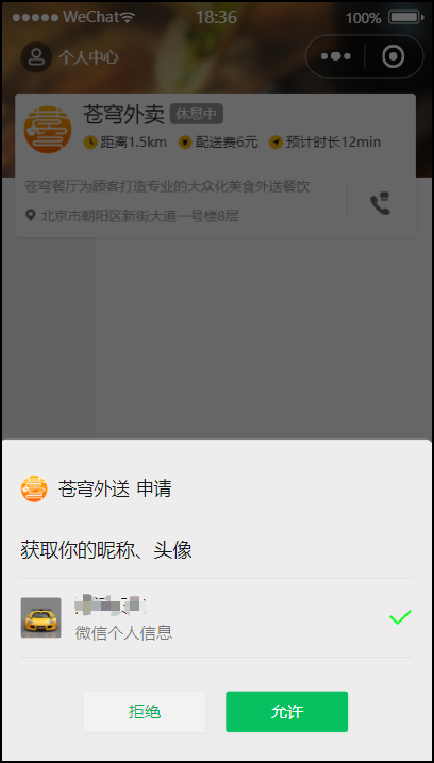 


**商品浏览效果图：**

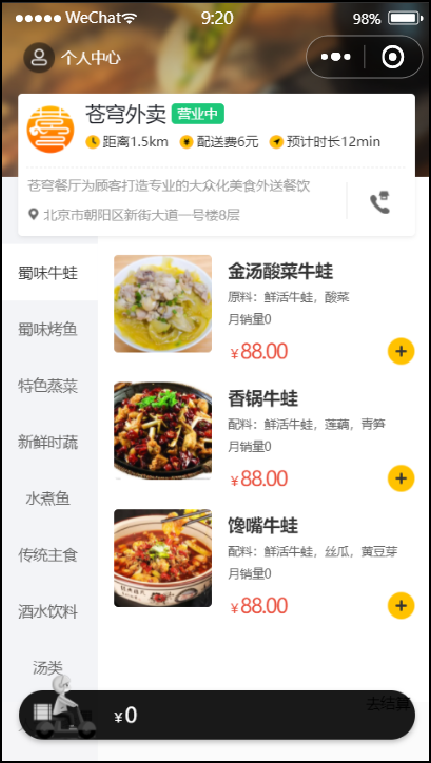 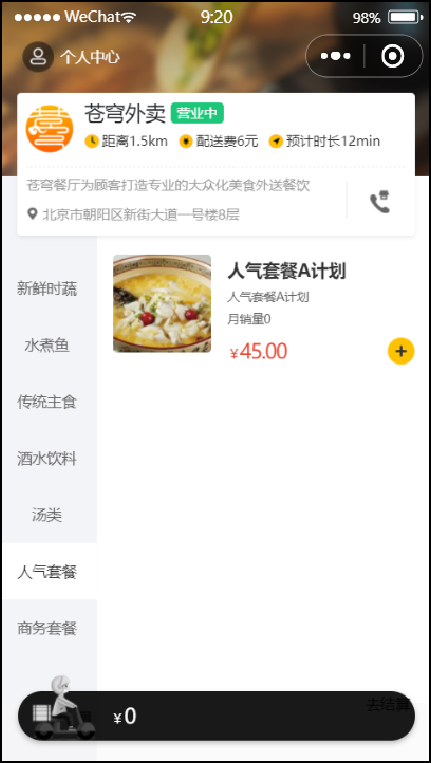


## 1. HttpClient

> **PPT对照：** 第4—11页。


### 1.1 介绍

> **PPT对照：** 第5—8页。

HttpClient 是Apache Jakarta Common 下的子项目，可以用来提供高效的、最新的、功能丰富的支持 HTTP 协议的客户端编程工具包，并且它支持 HTTP 协议最新的版本和建议。

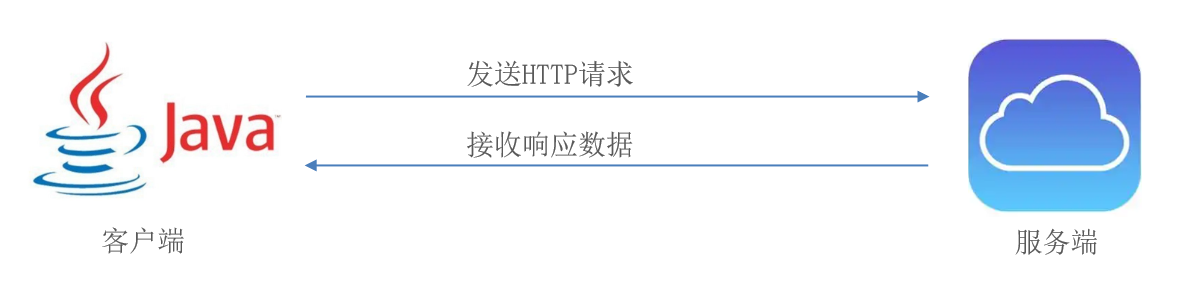 

**HttpClient作用：**

- 发送HTTP请求
- 接收响应数据

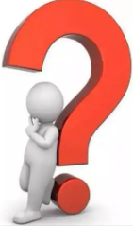  为什么要在Java程序中发送Http请求？有哪些应用场景呢？

**HttpClient应用场景：**

当我们在使用扫描支付、查看地图、获取验证码、查看天气等功能时

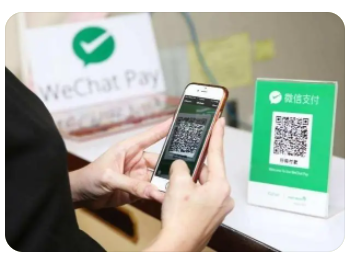  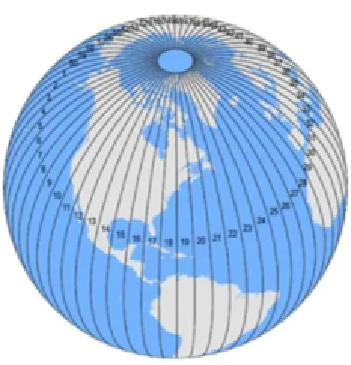   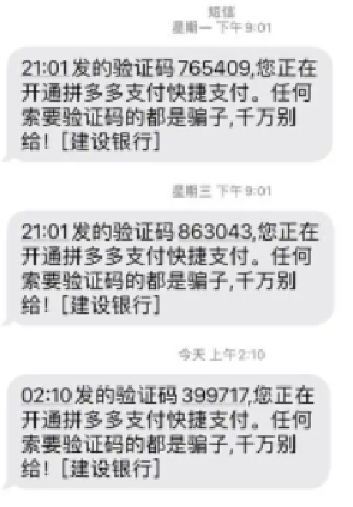   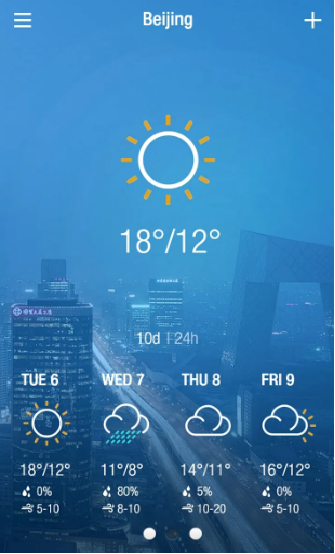 


其实，应用程序本身并未实现这些功能，都是在应用程序里访问提供这些功能的服务，访问这些服务需要发送HTTP请求，并且接收响应数据，可通过HttpClient来实现。

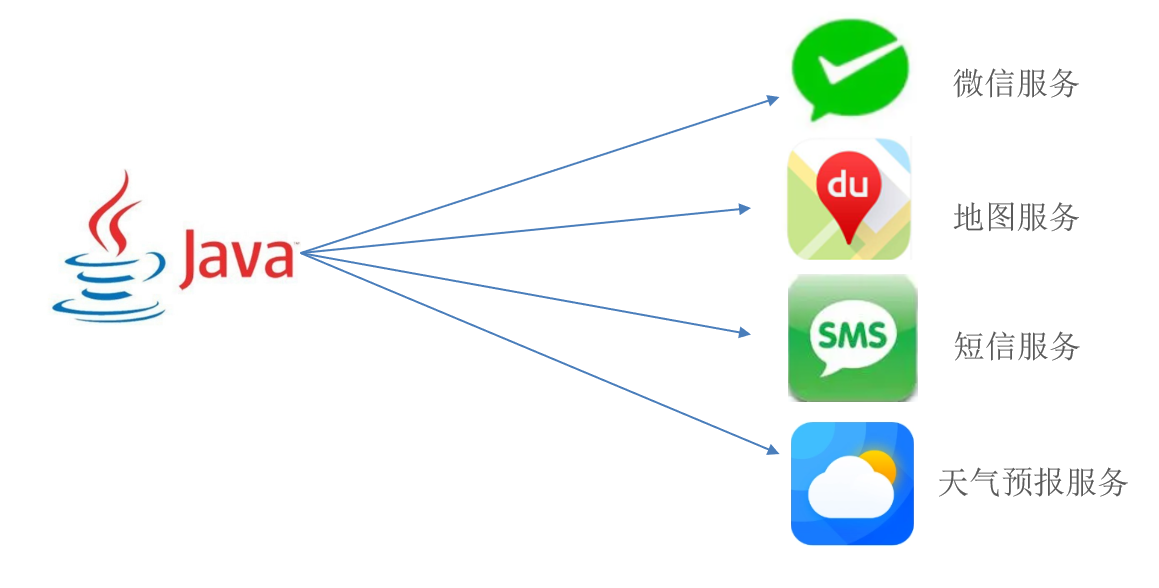 

**HttpClient的maven坐标：**

```xml
<dependency>
	<groupId>org.apache.httpcomponents</groupId>
	<artifactId>httpclient</artifactId>
	<version>4.5.13</version>
</dependency>
```

**HttpClient的核心API：**

- HttpClient：Http客户端对象类型，使用该类型对象可发起Http请求。
- HttpClients：可认为是构建器，可创建HttpClient对象。
- CloseableHttpClient：实现类，实现了HttpClient接口。
- HttpGet：Get方式请求类型。
- HttpPost：Post方式请求类型。

**HttpClient发送请求步骤：**

- 创建HttpClient对象
- 创建Http请求对象
- 调用HttpClient的execute方法发送请求


### HttpClient处于哪一段请求中（补充与勘误）

用户通过小程序请求我们的后端时，后端是HTTP服务端；后端为了换取openid再请求微信时，后端又是HTTP客户端。HttpClient负责第二段通信，不是Controller的替代品。

本章使用Apache HttpClient 4.5.13，API包名通常为 `org.apache.http...`。HttpClient 5使用不同依赖和包名，不能把两代示例混在一起。

原文称CloseableHttpClient为“实现类”，更准确地说它是实现HttpClient与Closeable的抽象类；HttpClients工厂返回可用的具体实现对象。GET、POST是请求对象，CloseableHttpResponse是响应资源。

课程已通过OSS SDK间接引入HttpClient，但直接使用某个库的API时，明确声明对应依赖能减少对传递依赖的偶然依赖。版本应与现有依赖管理一致，不为一个示例随意覆盖整个项目的版本。


### 1.2 入门案例

> **PPT对照：** 第10—11页。

对HttpClient编程工具包有了一定了解后，那么，我们使用HttpClient在Java程序当中来构造Http的请求，并且把请求发送出去，接下来，就通过入门案例分别发送**GET请求**和**POST请求**，具体来学习一下它的使用方法。

#### 1.2.1 GET方式请求

正常来说，首先，应该导入HttpClient相关的坐标，但在项目中，就算不导入，也可以使用相关的API。

因为在项目中已经引入了aliyun-sdk-oss坐标：

```xml
<dependency>
    <groupId>com.aliyun.oss</groupId>
    <artifactId>aliyun-sdk-oss</artifactId>
</dependency>
```

上述依赖的底层已经包含了HttpClient相关依赖。

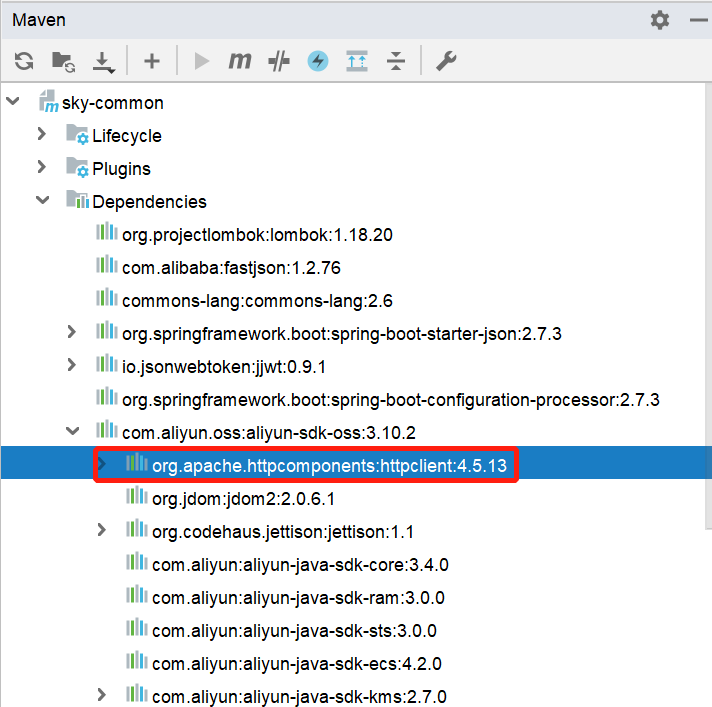 

故选择导入或者不导入均可。

进入到sky-server模块，编写测试代码，发送GET请求。

**实现步骤：**

1. 创建HttpClient对象
2. 创建请求对象
3. 发送请求，接受响应结果
4. 解析结果
5. 关闭资源

```java
package com.sky.test;

import org.apache.http.HttpEntity;
import org.apache.http.client.methods.CloseableHttpResponse;
import org.apache.http.client.methods.HttpGet;
import org.apache.http.impl.client.CloseableHttpClient;
import org.apache.http.impl.client.HttpClients;
import org.apache.http.util.EntityUtils;
import org.junit.jupiter.api.Test;
import org.springframework.boot.test.context.SpringBootTest;

@SpringBootTest
public class HttpClientTest {

    /**
     * 测试通过httpclient发送GET方式的请求
     */
    @Test
    public void testGET() throws Exception{
        //创建httpclient对象
        CloseableHttpClient httpClient = HttpClients.createDefault();

        //创建请求对象
        HttpGet httpGet = new HttpGet("http://localhost:8080/user/shop/status");

        //发送请求，接受响应结果
        CloseableHttpResponse response = httpClient.execute(httpGet);

        //获取服务端返回的状态码
        int statusCode = response.getStatusLine().getStatusCode();
        System.out.println("服务端返回的状态码为：" + statusCode);

        HttpEntity entity = response.getEntity();
        String body = EntityUtils.toString(entity);
        System.out.println("服务端返回的数据为：" + body);

        //关闭资源
        response.close();
        httpClient.close();
    }
}
```

在访问http://localhost:8080/user/shop/status请求时，需要提前启动项目。

**测试结果：**

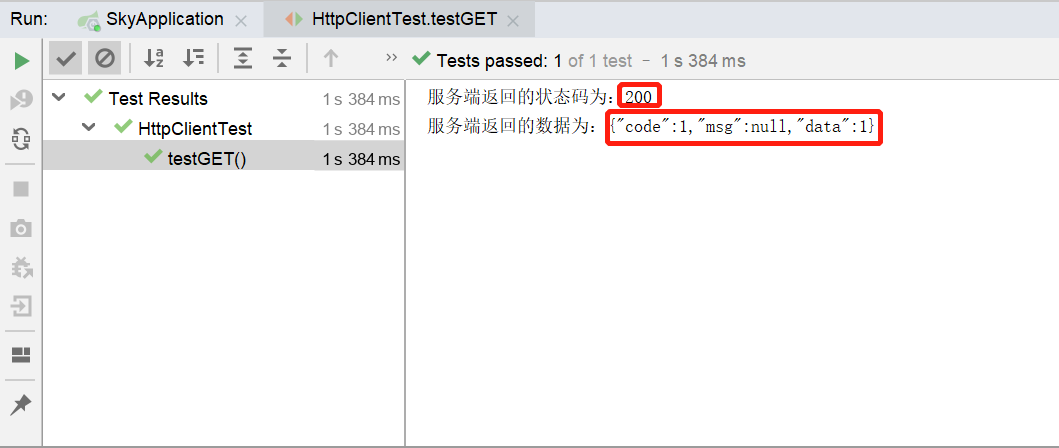 


#### 1.2.2 POST方式请求

在HttpClientTest中添加POST方式请求方法，相比GET请求来说，POST请求若携带参数需要封装请求体对象，并将该对象设置在请求对象中。

**实现步骤：**

1. 创建HttpClient对象
2. 创建请求对象
3. 发送请求，接收响应结果
4. 解析响应结果
5. 关闭资源

```java
	/**
     * 测试通过httpclient发送POST方式的请求
     */
    @Test
    public void testPOST() throws Exception{
        // 创建httpclient对象
        CloseableHttpClient httpClient = HttpClients.createDefault();

        //创建请求对象
        HttpPost httpPost = new HttpPost("http://localhost:8080/admin/employee/login");

        JSONObject jsonObject = new JSONObject();
        jsonObject.put("username","admin");
        jsonObject.put("password","123456");

        StringEntity entity = new StringEntity(jsonObject.toString());
        //指定请求编码方式
        entity.setContentEncoding("utf-8");
        //数据格式
        entity.setContentType("application/json");
        httpPost.setEntity(entity);

        //发送请求
        CloseableHttpResponse response = httpClient.execute(httpPost);

        //解析返回结果
        int statusCode = response.getStatusLine().getStatusCode();
        System.out.println("响应码为：" + statusCode);

        HttpEntity entity1 = response.getEntity();
        String body = EntityUtils.toString(entity1);
        System.out.println("响应数据为：" + body);

        //关闭资源
        response.close();
        httpClient.close();
    }
```

**测试结果：**

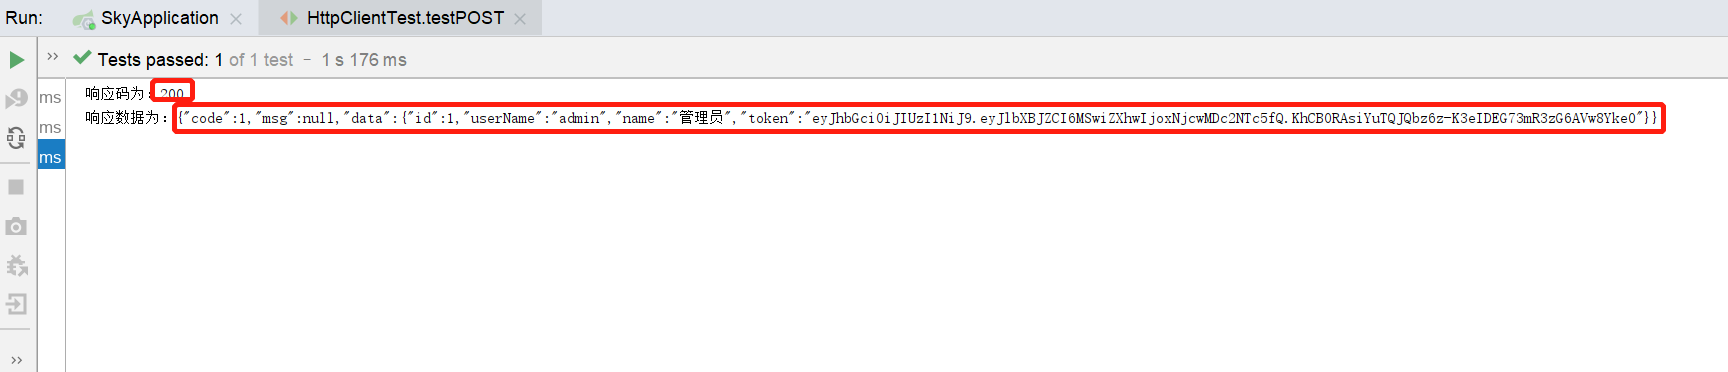


### HTTP示例需要补全的处理（补充与勘误）

#### JSON请求的编码

原POST先 `new StringEntity(jsonObject.toString())`，再setContentEncoding("utf-8")。Content-Encoding用于内容编码，例如压缩，它不是字符集；后设这个header也不会重新编码已经生成的请求字节。建议在创建entity时指定JSON与UTF-8：

```java
import java.nio.charset.StandardCharsets;
import org.apache.http.entity.ContentType;
import org.apache.http.entity.StringEntity;

StringEntity entity = new StringEntity(jsonObject.toJSONString(),
        ContentType.create("application/json", StandardCharsets.UTF_8));
httpPost.setEntity(entity);
```

补充片段放在原方法中，不再调用setContentEncoding。POST方法还需补HttpPost、StringEntity和fastjson.JSONObject等imports。

#### 资源关闭与超时

原样例在最后close，前面的execute或读取若抛异常，就可能没有执行关闭。单次请求练习可用try-with-resources；以下替换原GET方法，原类已有HttpClient与响应相关imports：

```java
@Test
public void testGET() throws Exception {
    org.apache.http.client.config.RequestConfig config =
            org.apache.http.client.config.RequestConfig.custom()
                    .setConnectTimeout(5000)
                    .setConnectionRequestTimeout(5000)
                    .setSocketTimeout(5000)
                    .build();
    try (CloseableHttpClient client = HttpClients.custom()
            .setDefaultRequestConfig(config).build()) {
        HttpGet request = new HttpGet("http://localhost:8080/user/shop/status");
        try (CloseableHttpResponse response = client.execute(request)) {
            int status = response.getStatusLine().getStatusCode();
            if (status < 200 || status >= 300) {
                throw new IllegalStateException("HTTP调用失败，状态码=" + status);
            }
            HttpEntity entity = response.getEntity();
            String body = entity == null ? "" : EntityUtils.toString(entity,
                    java.nio.charset.StandardCharsets.UTF_8);
            System.out.println(body);
        }
    }
}
```

5000的单位是毫秒，分别约束连接、从连接池获取连接、等待数据的过程，不表示整个调用必定在5秒内结束。实际服务通常复用受管理的连接池客户端，响应仍应及时关闭；不要在每次业务请求后关闭全局共享客户端。

HTTP 200只表示这一层请求完成，不等于JSON里的业务code成功，更不等于微信响应有openid。应分别检查HTTP状态、响应格式和业务状态。

`@SpringBootTest`默认测试环境不会自动在8080启动真实监听服务。原示例请求localhost:8080前，要另行启动后端；若改成随机端口测试，则相应读取真实端口，不能照抄固定地址。

GET请求参数建议用URIBuilder编码，JSON POST用请求体；不要手工拼含空格、中文或特殊字符的查询串。登录响应里的token和微信会话信息不应直接打印到共享日志。


## 2. 微信小程序开发

> **PPT对照：** 第13—36页。


### 2.1 介绍

> **PPT对照：** 第14—17页。

小程序是一种新的开放能力，开发者可以快速地开发一个小程序。可以在微信内被便捷地获取和传播，同时具有出色的使用体验。

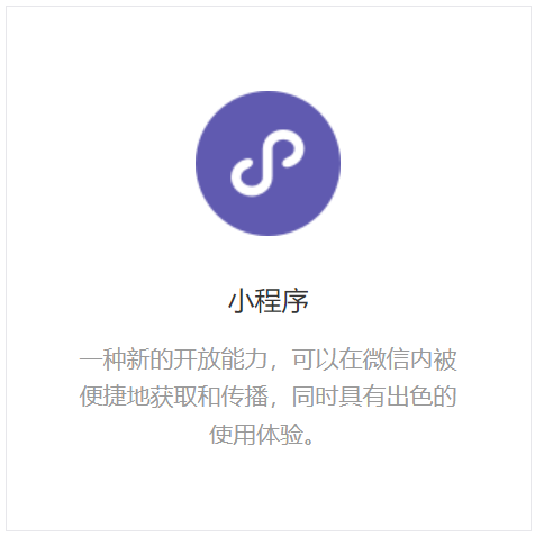 

**官方网址：**https://mp.weixin.qq.com/cgi-bin/wx?token=&lang=zh_CN

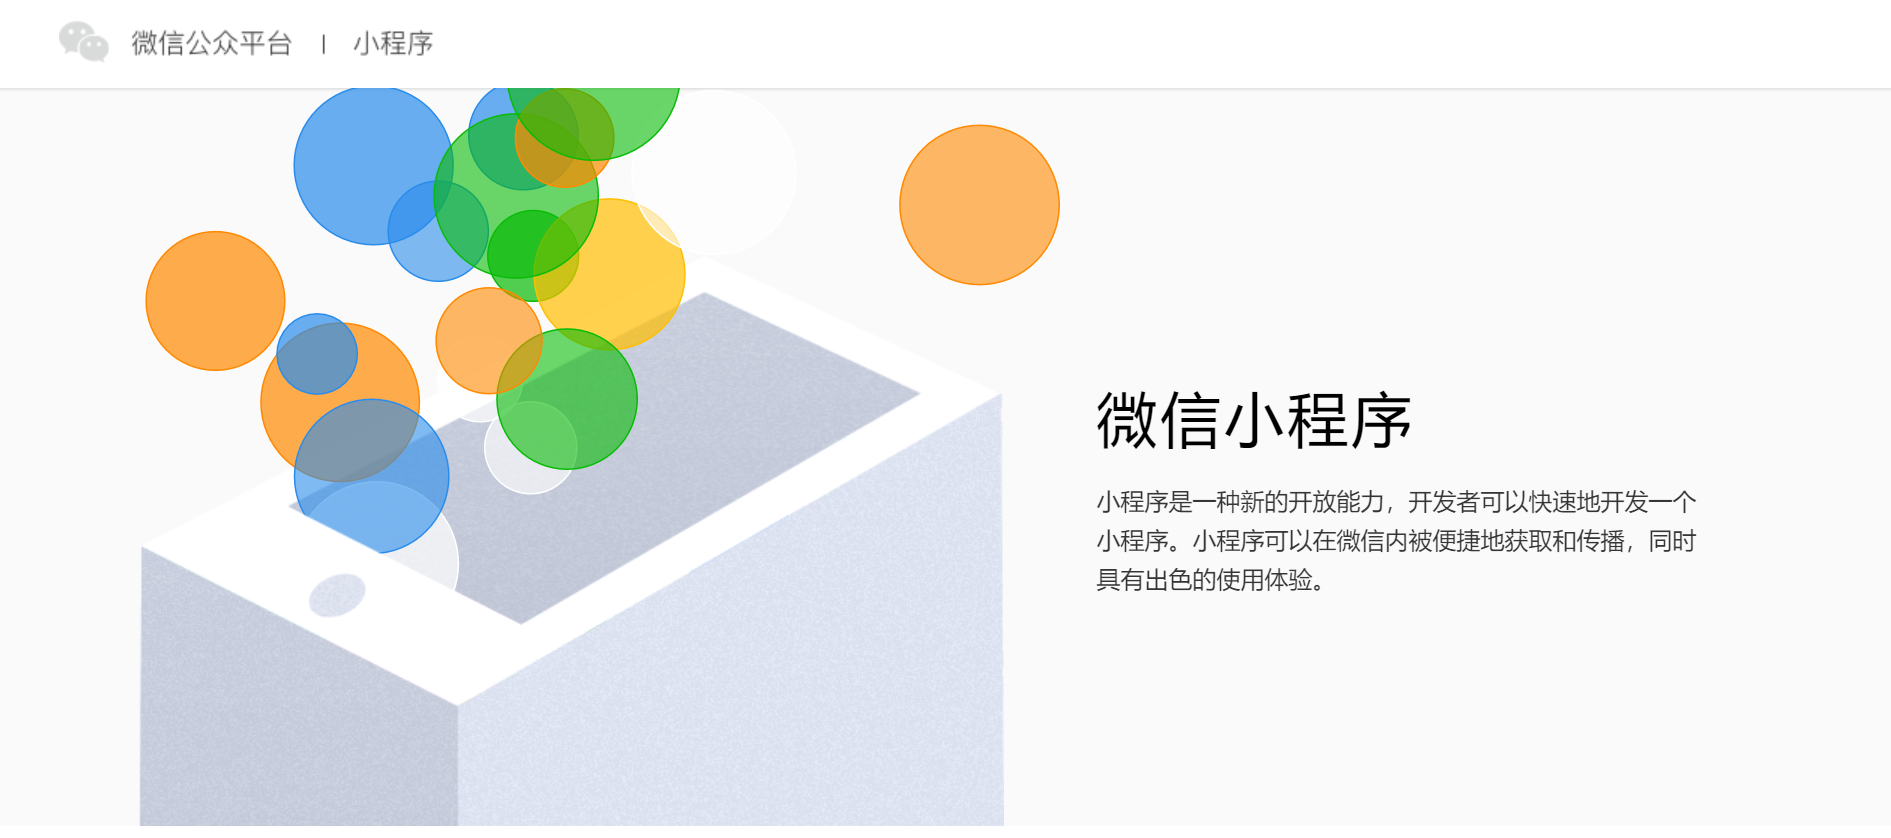 

小程序主要运行微信内部，可通过上述网站来整体了解微信小程序的开发。

**首先，**在进行小程序开发时，需要先去注册一个小程序，在注册的时候，它实际上又分成了不同的注册的主体。我们可以以个人的身份来注册一个小程序，当然，也可以以企业政府、媒体或者其他组织的方式来注册小程序。那么，不同的主体注册小程序，最终开放的权限也是不一样的。比如以个人身份来注册小程序，是无法开通支付权限的。若要提供支付功能，必须是企业、政府或者其它组织等。所以，不同的主体注册小程序后，可开发的功能是不一样的。

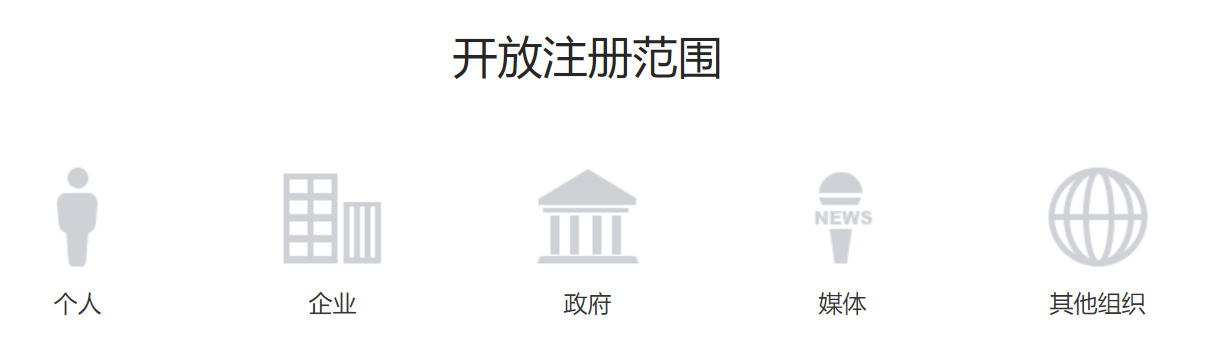 


**然后，**微信小程序我们提供的一些开发的支持，实际上微信的官方是提供了一系列的工具来帮助开发者快速的接入
并且完成小程序的开发，提供了完善的开发文档，并且专门提供了一个开发者工具，还提供了相应的设计指南，同时也提供了一些小程序体验DEMO，可以快速的体验小程序实现的功能。

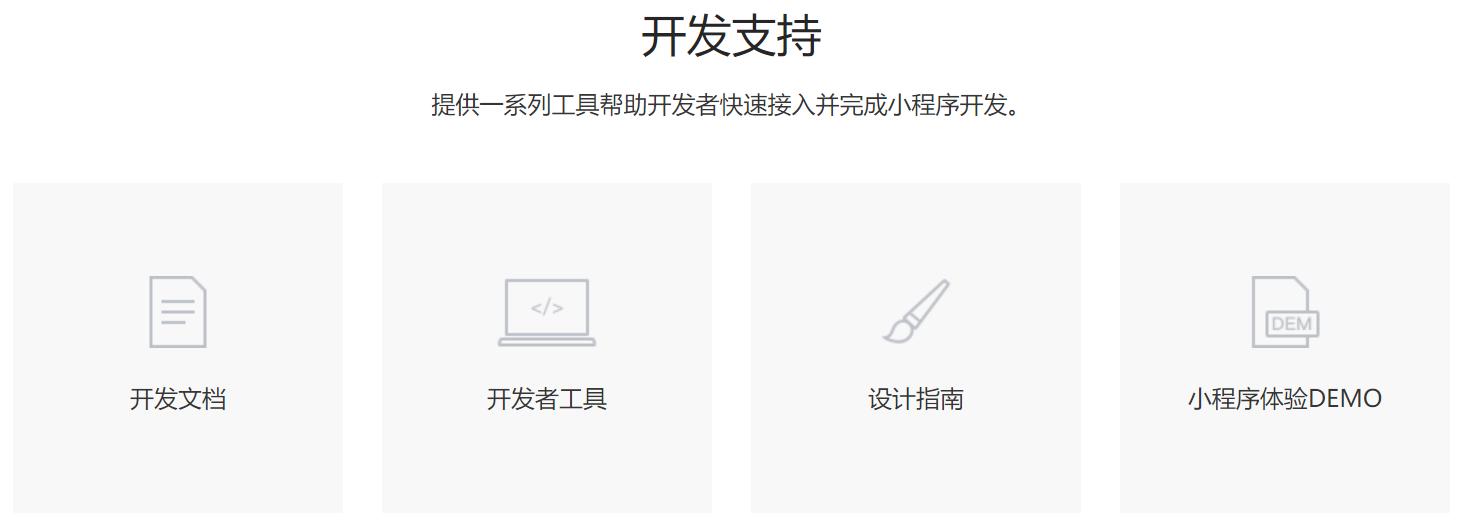 

**最后，**开发完一个小程序要上线，也给我们提供了详细地接入流程。

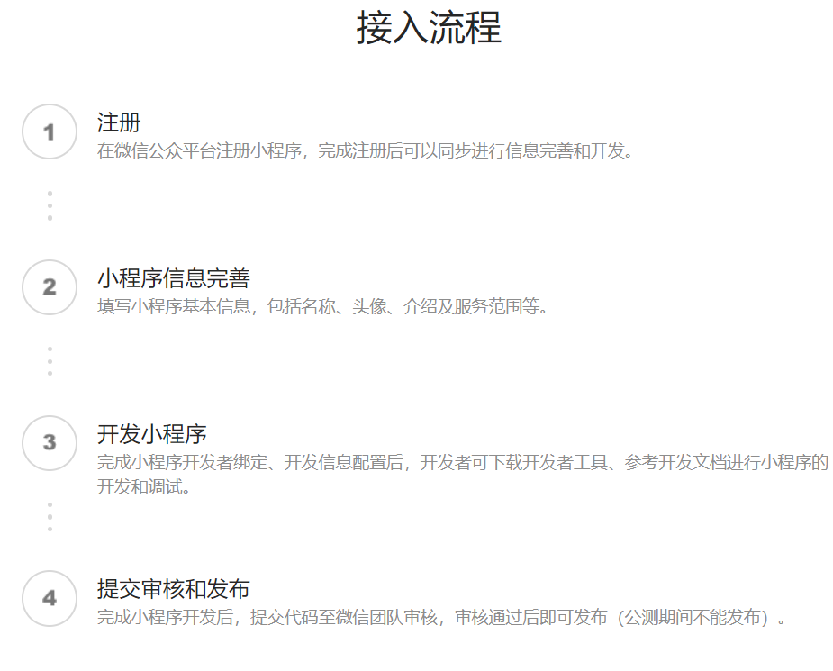


### 小程序登录与资料授权的边界（补充）

小程序代码运行在微信提供的环境中，不能把浏览器的DOM操作或所有浏览器API直接搬进去。WXML/WXSS与HTML/CSS有相似用途，但不是同一种运行环境。

wx.login用于获取临时登录凭证；头像、昵称、手机号属于其他资料或能力。通过code2Session不会自动拿到这些字段。原文按注册主体介绍支付和手机号权限，具体开放能力还取决于主体、类目、认证及平台当前规则，不能把旧资料的概括当作当前全部准入条件。

本章登录只提交code并保存openid、createTime，资料收集应在后续明确授权的流程中实现。


### 2.2 准备工作

> **PPT对照：** 第19—28页。

开发微信小程序之前需要做如下准备工作：

- 注册小程序
- 完善小程序信息
- 下载开发者工具

**1). 注册小程序**

注册地址：https://mp.weixin.qq.com/wxopen/waregister?action=step1

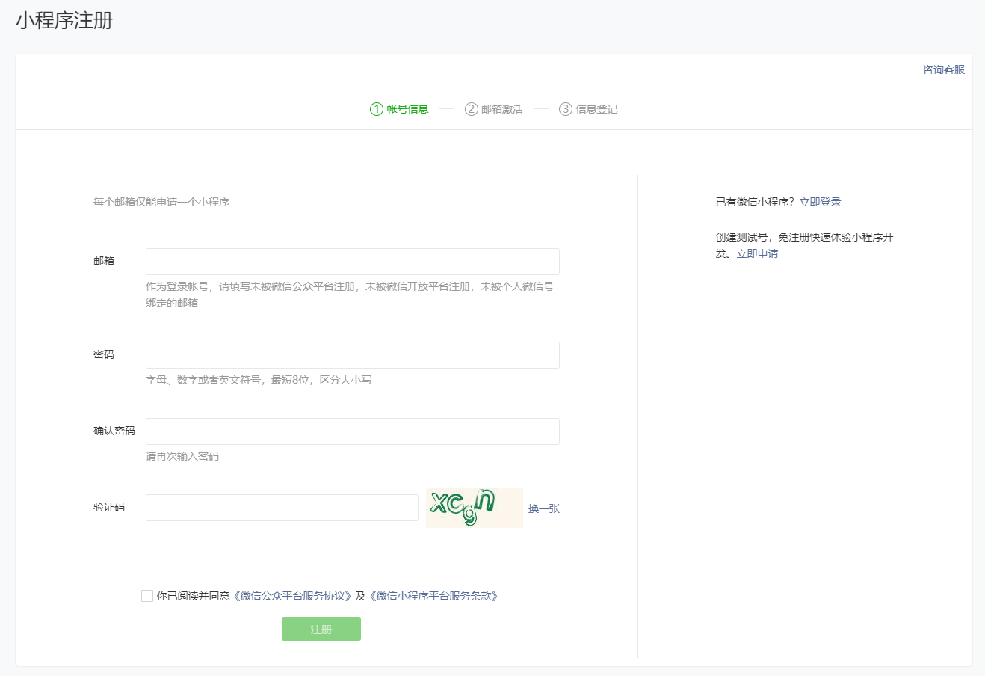 


**2). 完善小程序信息**

登录小程序后台：https://mp.weixin.qq.com/

两种登录方式选其一即可

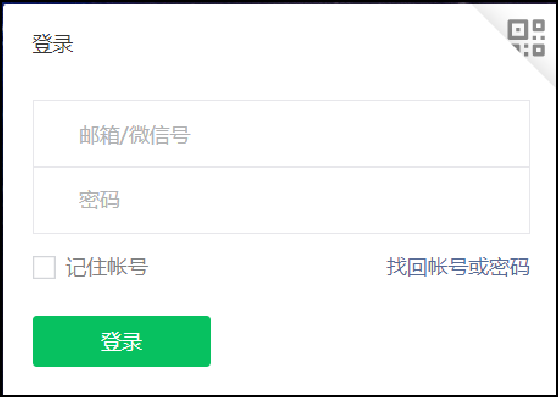 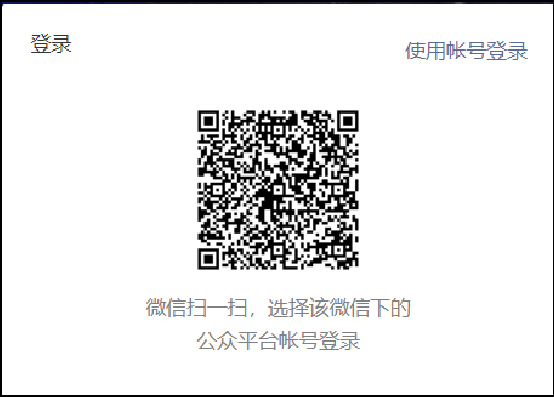 

完善小程序信息、小程序类目

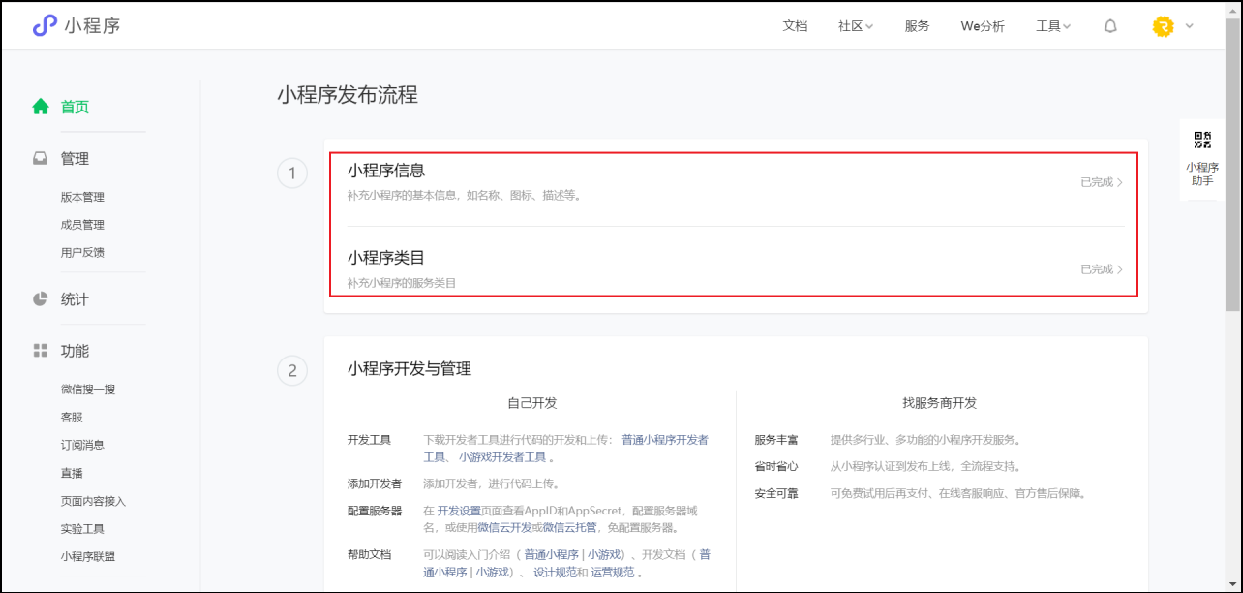 

查看小程序的 AppID

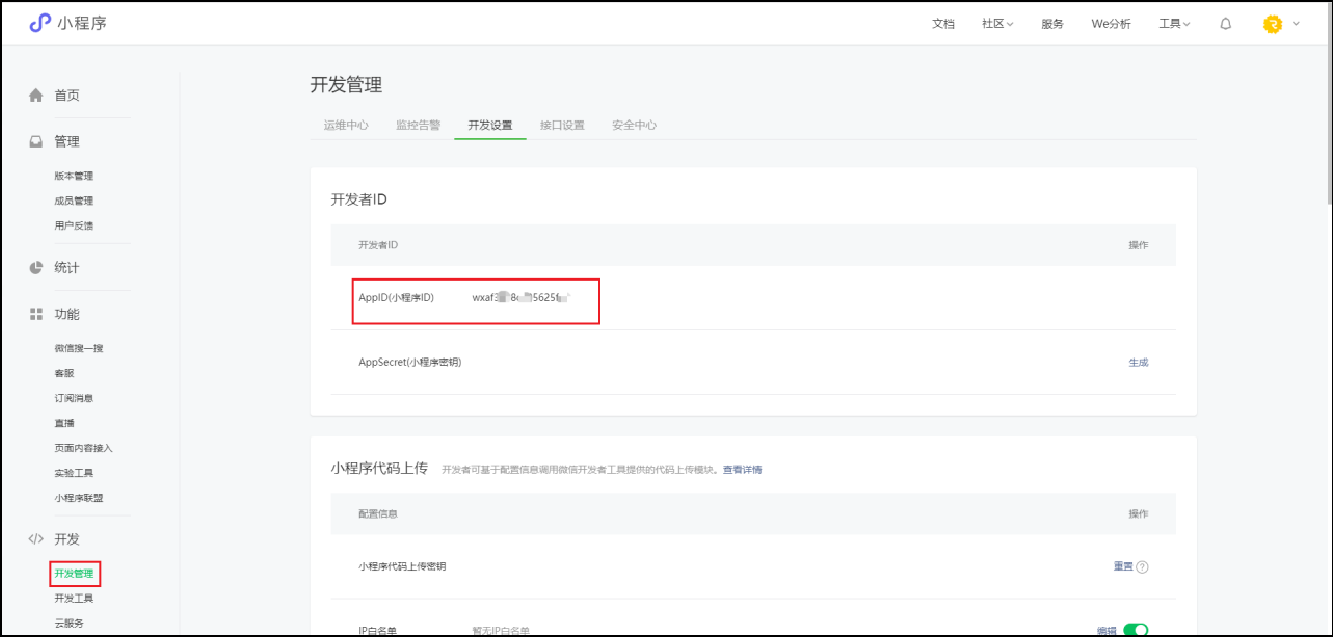 


**3). 下载开发者工具**

资料中已提供，无需下载，熟悉下载步骤即可。

下载地址： https://developers.weixin.qq.com/miniprogram/dev/devtools/stable.html

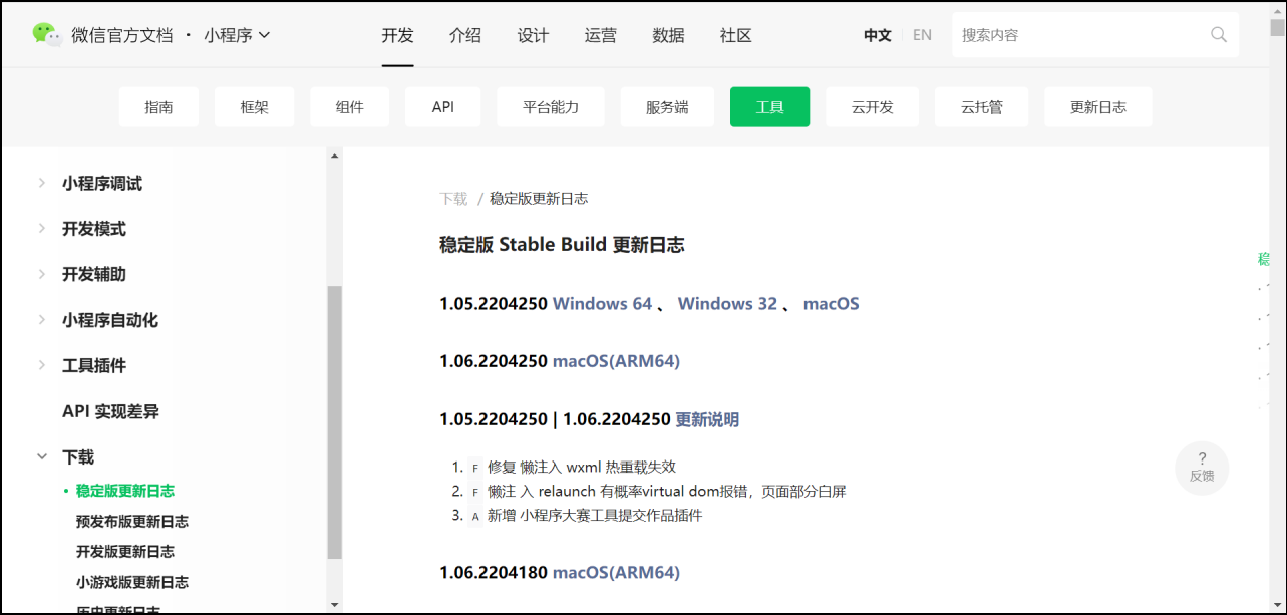 

扫描登录开发者工具

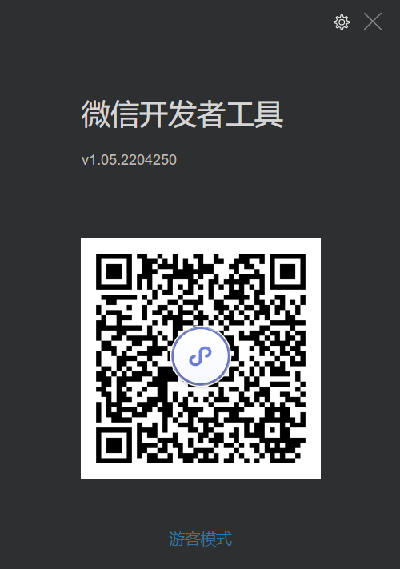 

创建小程序项目

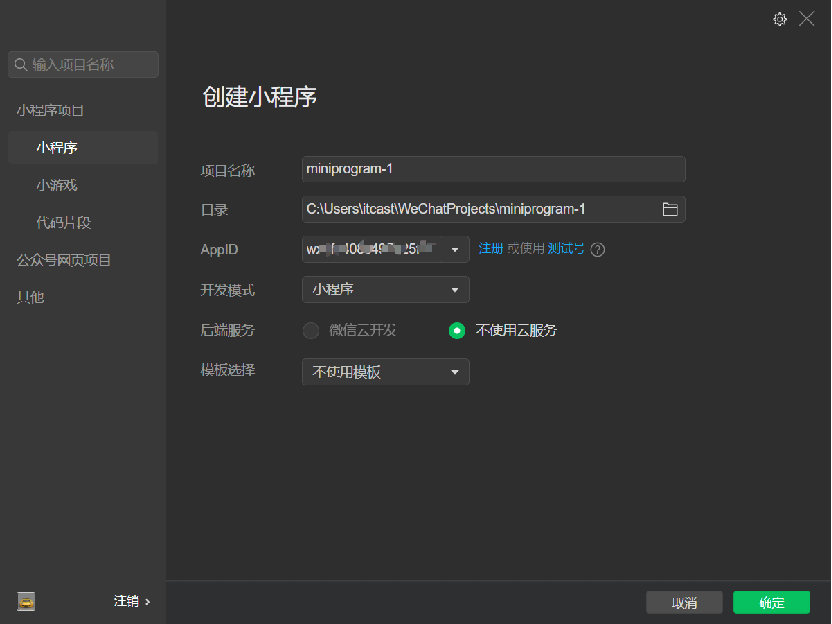 

熟悉开发者工具布局

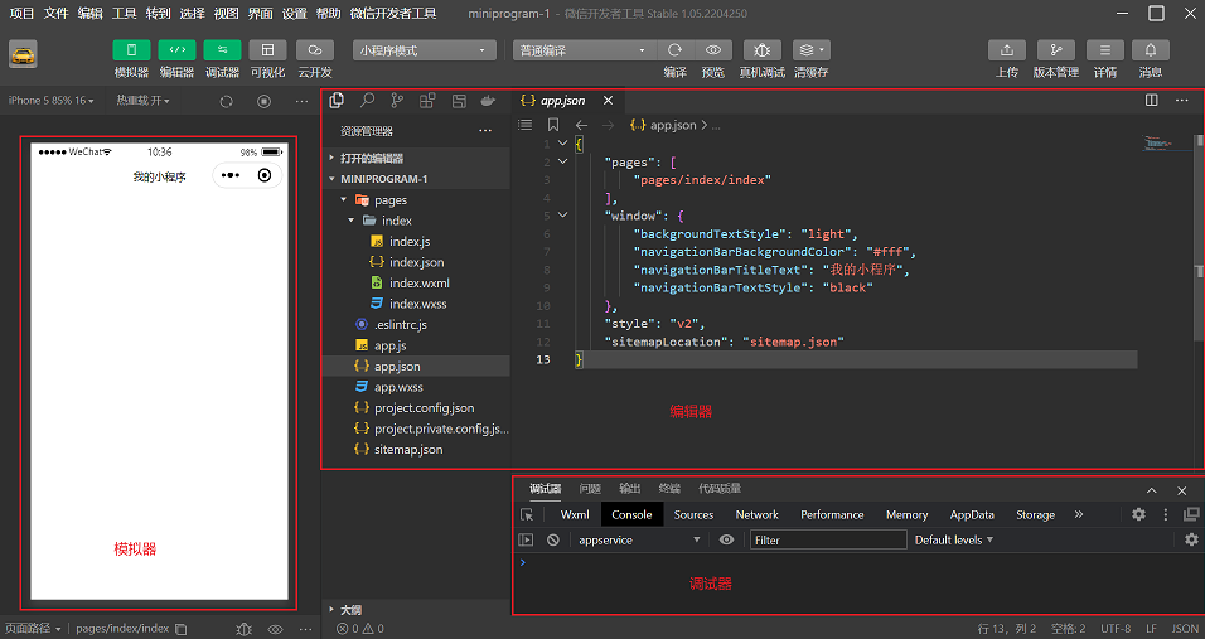 

设置不校验合法域名

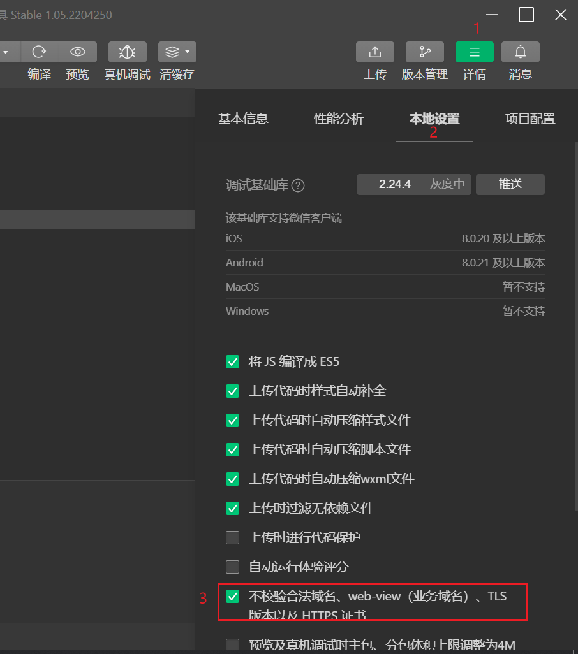 

**注：**开发阶段，小程序发出请求到后端的Tomcat服务器，若不勾选，请求发送失败。


### AppID与网络配置核对（补充）

AppID表示是哪一个小程序，开发者工具导入时选择的AppID必须与后端配置对应；AppSecret只供后端调用微信接口使用。使用老师的配置或不同账号的AppID/Secret组合，无法可靠完成自己的登录。

“不校验合法域名”是开发者工具的本地调试选项，不会为线上小程序配置正式请求域名。上线按平台要求配置合法域名与HTTPS等条件，上传、审核和发布是不同阶段。

模拟器里的localhost可能指开发电脑，真机里的localhost指手机本身；真机调试需要手机可访问的服务地址，并检查网络与服务器监听配置。不勾选调试选项不是所有请求失败的唯一原因，服务未启动、端口错误、网络不可达也会失败。

本笔记说明注册和发布流程，不替你注册账号、重置AppSecret或发布小程序。


### 2.3 入门案例

> **PPT对照：** 第30—36页；发布流程由讲义进一步展开。

实际上，小程序的开发本质上属于前端开发，主要使用JavaScript开发，咱们现在的定位主要还是在后端，所以，对于小程序开发简单了解即可。

#### 2.3.1 小程序目录结构

小程序包含一个描述整体程序的 app 和多个描述各自页面的 page。一个小程序主体部分由三个文件组成，必须放在项目的根目录，如下：

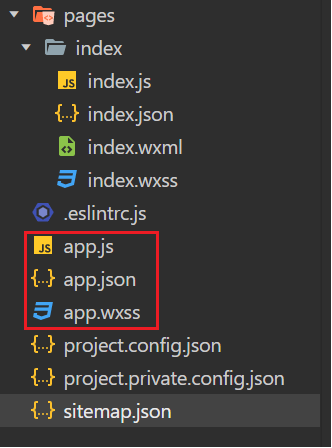 

**文件说明：**

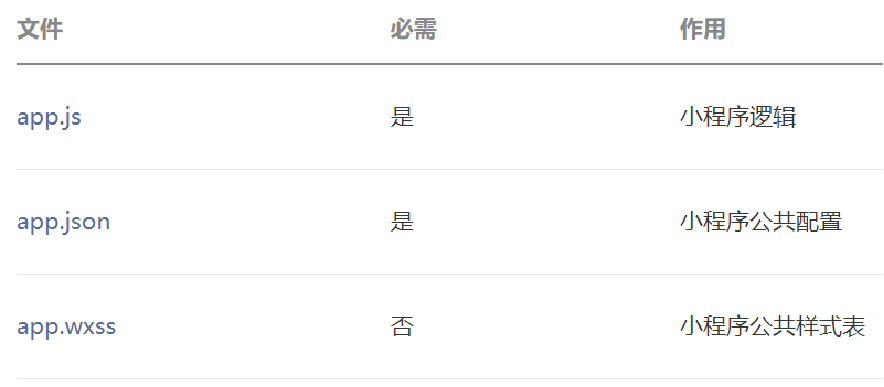 

**app.js：**必须存在，主要存放小程序的逻辑代码

**app.json：**必须存在，小程序配置文件，主要存放小程序的公共配置

**app.wxss:**  非必须存在，主要存放小程序公共样式表，类似于前端的CSS样式

对小程序主体三个文件了解后，其实一个小程序又有多个页面。比如说，有商品浏览页面、购物车的页面、订单支付的页面、商品的详情页面等等。那这些页面会放在哪呢？
会存放在pages目录。

每个小程序页面主要由四个文件组成：

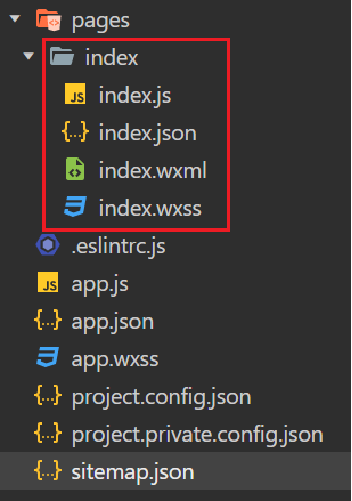 

**文件说明：**

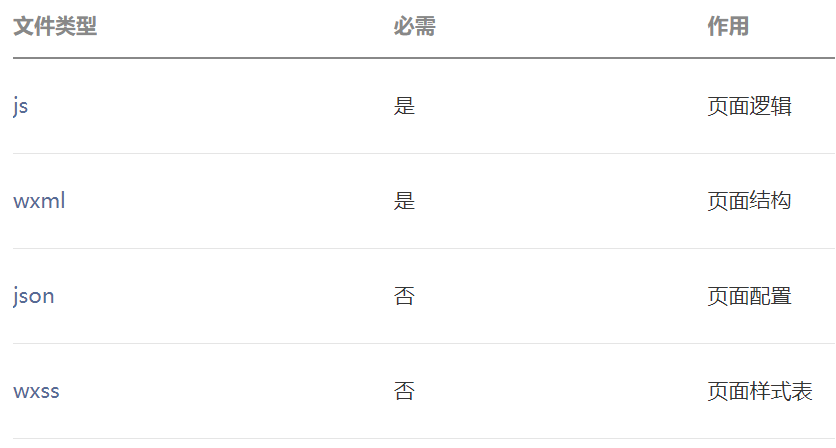 

**js文件：**必须存在，存放页面业务逻辑代码，编写的js代码。

**wxml文件：**必须存在，存放页面结构，主要是做页面布局，页面效果展示的，类似于HTML页面。

**json文件：**非必须，存放页面相关的配置。

**wxss文件：**非必须，存放页面样式表，相当于CSS文件。


#### 2.3.2 编写和编译小程序

**1). 编写**

进入到index.wxml，编写页面布局

```xml
<view class="container">
  <view>{{msg}}</view>
   <view>
    <button type="default" bindtap="getUserInfo">获取用户信息</button>
    <image style="width: 100px;height: 100px;" src="{{avatarUrl}}"></image>
    {{nickName}}
  </view>
   <view>
    <button type="primary" bindtap="wxlogin">微信登录</button>
    授权码：{{code}}
  </view>
   <view>
    <button type="warn" bindtap="sendRequest">发送请求</button>
    响应结果：{{result}}
  </view>
</view>
```

进入到index.js，编写业务逻辑代码

```javascript
Page({
  data:{
    msg:'hello world',
    avatarUrl:'',
    nickName:'',
    code:'',
    result:''
  },
  getUserInfo:function(){
    wx.getUserProfile({
      desc: '获取用户信息',
      success:(res) => {
        console.log(res)
        this.setData({
          avatarUrl:res.userInfo.avatarUrl,
          nickName:res.userInfo.nickName
        })
      }
    })
  },
  wxlogin:function(){
    wx.login({
      success: (res) => {
        console.log("授权码："+res.code)
        this.setData({
          code:res.code
        })
      }
    })
  },
  sendRequest:function(){
    wx.request({
      url: 'http://localhost:8080/user/shop/status',
      method:'GET',
      success:(res) => {
        console.log("响应结果：" + res.data.data)
        this.setData({
          result:res.data.data
        })
      }
    })
  }})
```


**2). 编译**

点击编译按钮

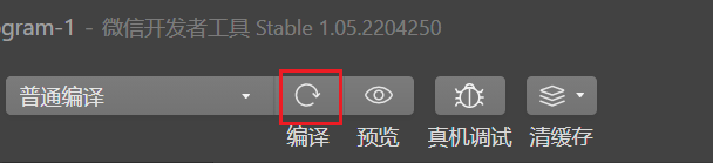 


**3). 运行效果**

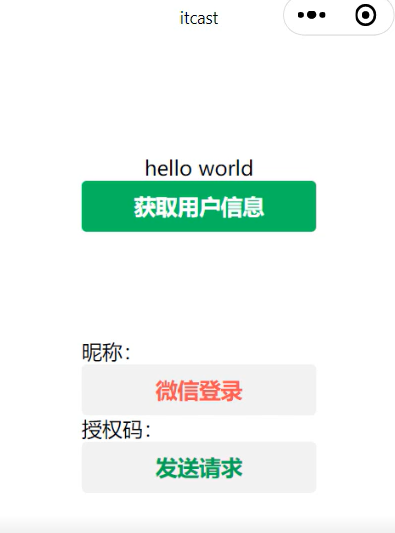 


点击**获取用户信息**

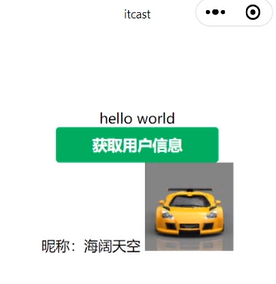 


点击**微信登录**

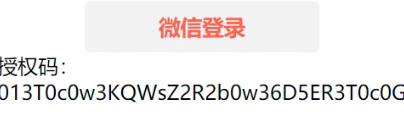 


点击**发送请求**

因为请求http://localhost:8080/user/shop/status，先要启动后台项目。

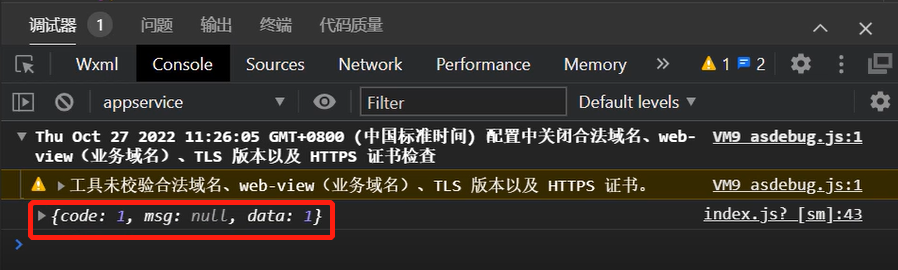 

**注：**设置不校验合法域名，若不勾选，请求发送失败。


#### 2.3.3 发布小程序

小程序的代码都已经开发完毕，要将小程序发布上线，让所有的用户都能使用到这个小程序。

点击上传按钮：

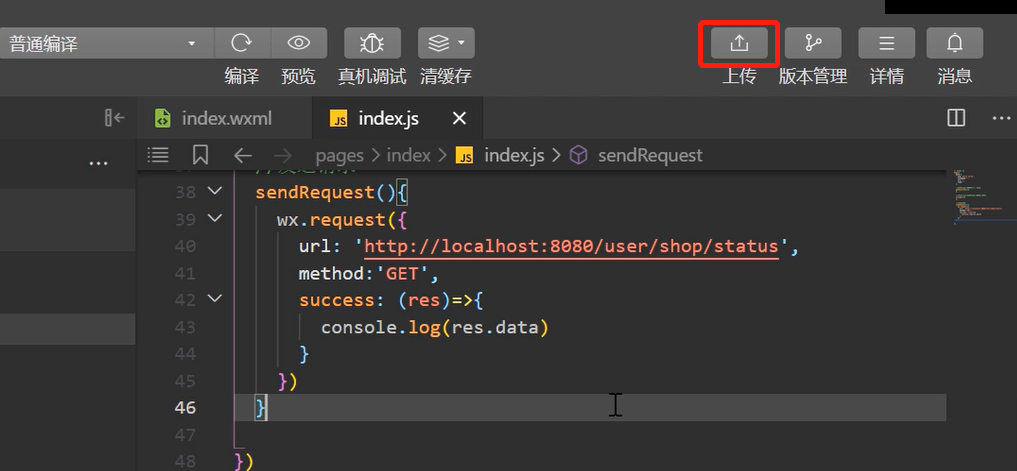 

指定版本号：

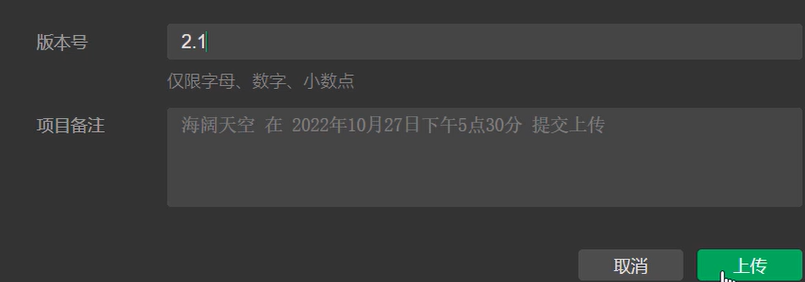 

上传成功：

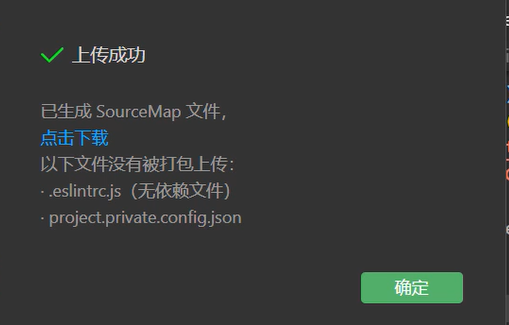 

把代码上传到微信服务器就表示小程序已经发布了吗？
**其实并不是。**当前小程序版本只是一个开发版本。

进到微信公众平台，打开版本管理页面。

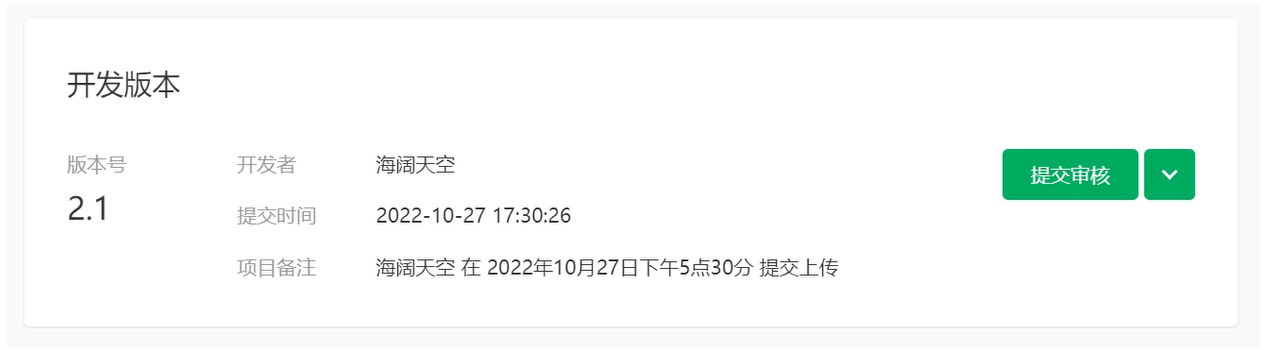 

需提交审核，变成审核版本，审核通过后，进行发布，变成线上版本。

一旦成为线上版本，这就说明小程序就已经发布上线了，微信用户就可以在微信里面去搜索和使用这个小程序了。


### 看懂小程序页面与异步请求（补充与勘误）

| 文件或写法 | 作用 |
| --- | --- |
| app.js / app.json / app.wxss | 应用逻辑、全局配置与公共样式 |
| pages下的js / wxml / json / wxss | 页面逻辑、结构、配置与样式 |
| {{msg}} | WXML读取data中的字段 |
| bindtap | 把点击事件绑定到页面方法 |
| this.setData | 更新用于页面显示的数据 |
| wx.login / wx.request | 异步获取code、发送网络请求 |

原资料含一些不可见的不换行空格，代码复制到编辑器后若解析异常，检查缩进和字符，不要只看它们显示得像普通空格。

原 `wx.getUserProfile` 的头像昵称获取方式有版本和平台规则背景，旧样例不保证当前环境仍能拿到预期的真实资料。实际资料完善应采用平台当前支持的头像选择、昵称输入等方式；登录身份判定不能依赖头像或昵称是否拿到。

`wx.request`的success回调表示收到HTTP响应，4xx/5xx也可能进入success；fail通常是网络等调用失败。`res.data`是服务器响应体，课程Result的业务结果在 `res.data.data`，不能忽略statusCode和业务code就直接读取它。

wx.login与wx.request异步执行，调用wx.login后立刻访问this.data.code，可能尚未更新。把提交code的请求放进登录成功回调，并检查res.code存在；失败和401分别处理，避免显示旧状态或用旧code重试。

代码上传后仍是开发版本，审核通过也还需发布才成为线上版本；编译、上传、审核、发布不是同一步操作。


## 3. 微信登录

> **PPT对照：** 第38—62页。


### 3.1 导入小程序代码

> **PPT对照：** 第39页。

开发微信小程序，本质上是属于前端的开发，我们的重点其实还是后端代码开发。所以，小程序的代码已经提供好了，直接导入到微信开发者工具当中，直接来使用就可以了。

**1). 找到资料**

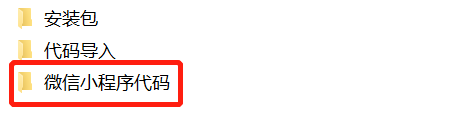 


**2). 导入代码**

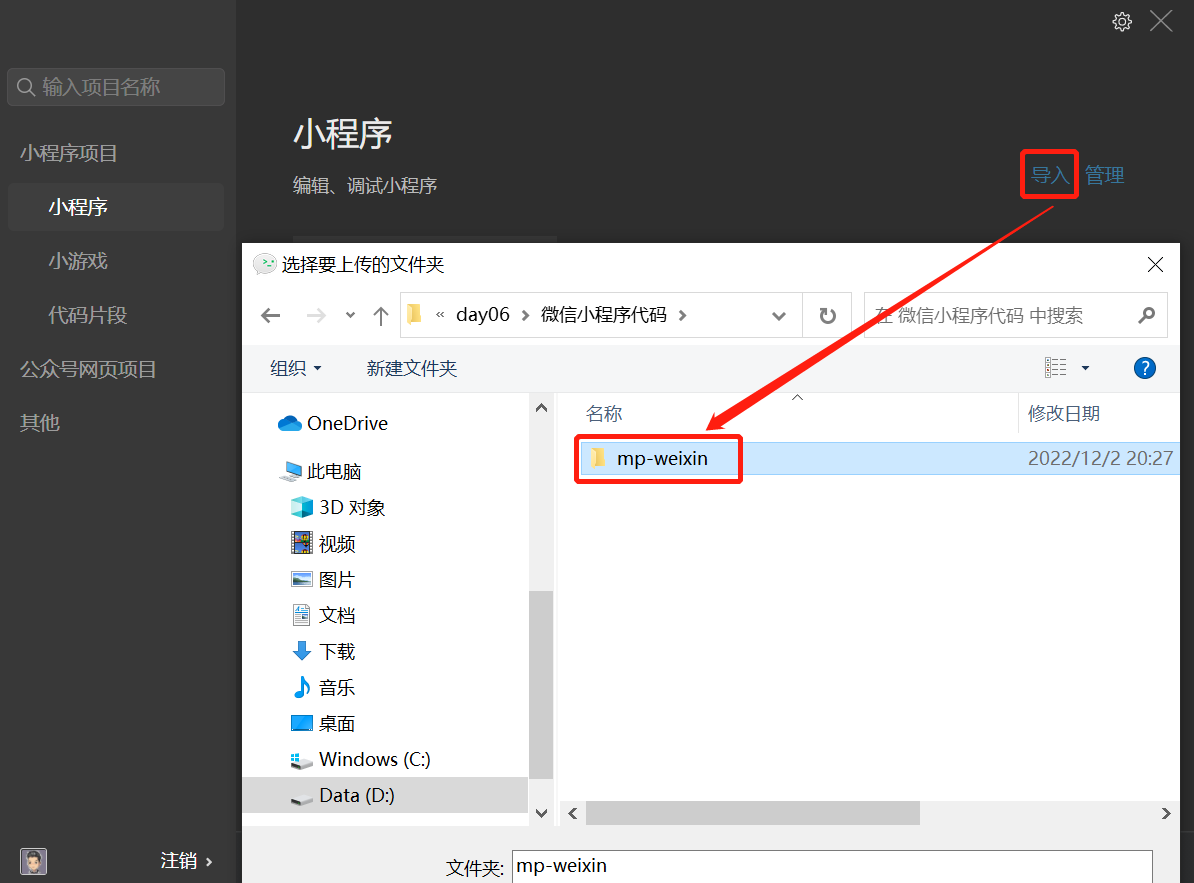 

AppID：使用自己的AppID

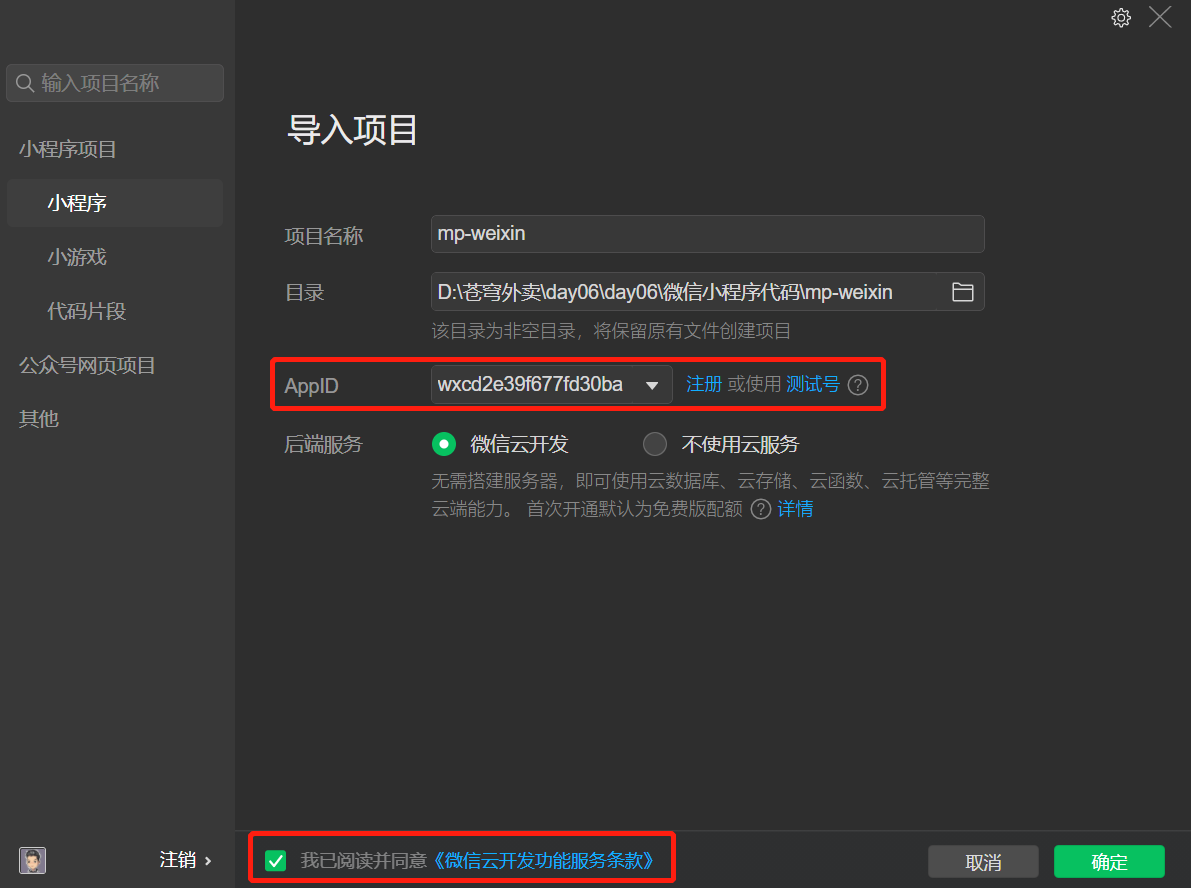 


**3). 查看项目结构**

主体的文件:app.js app.json app.wxss
项目的页面比较多，主要存放在pages目录。

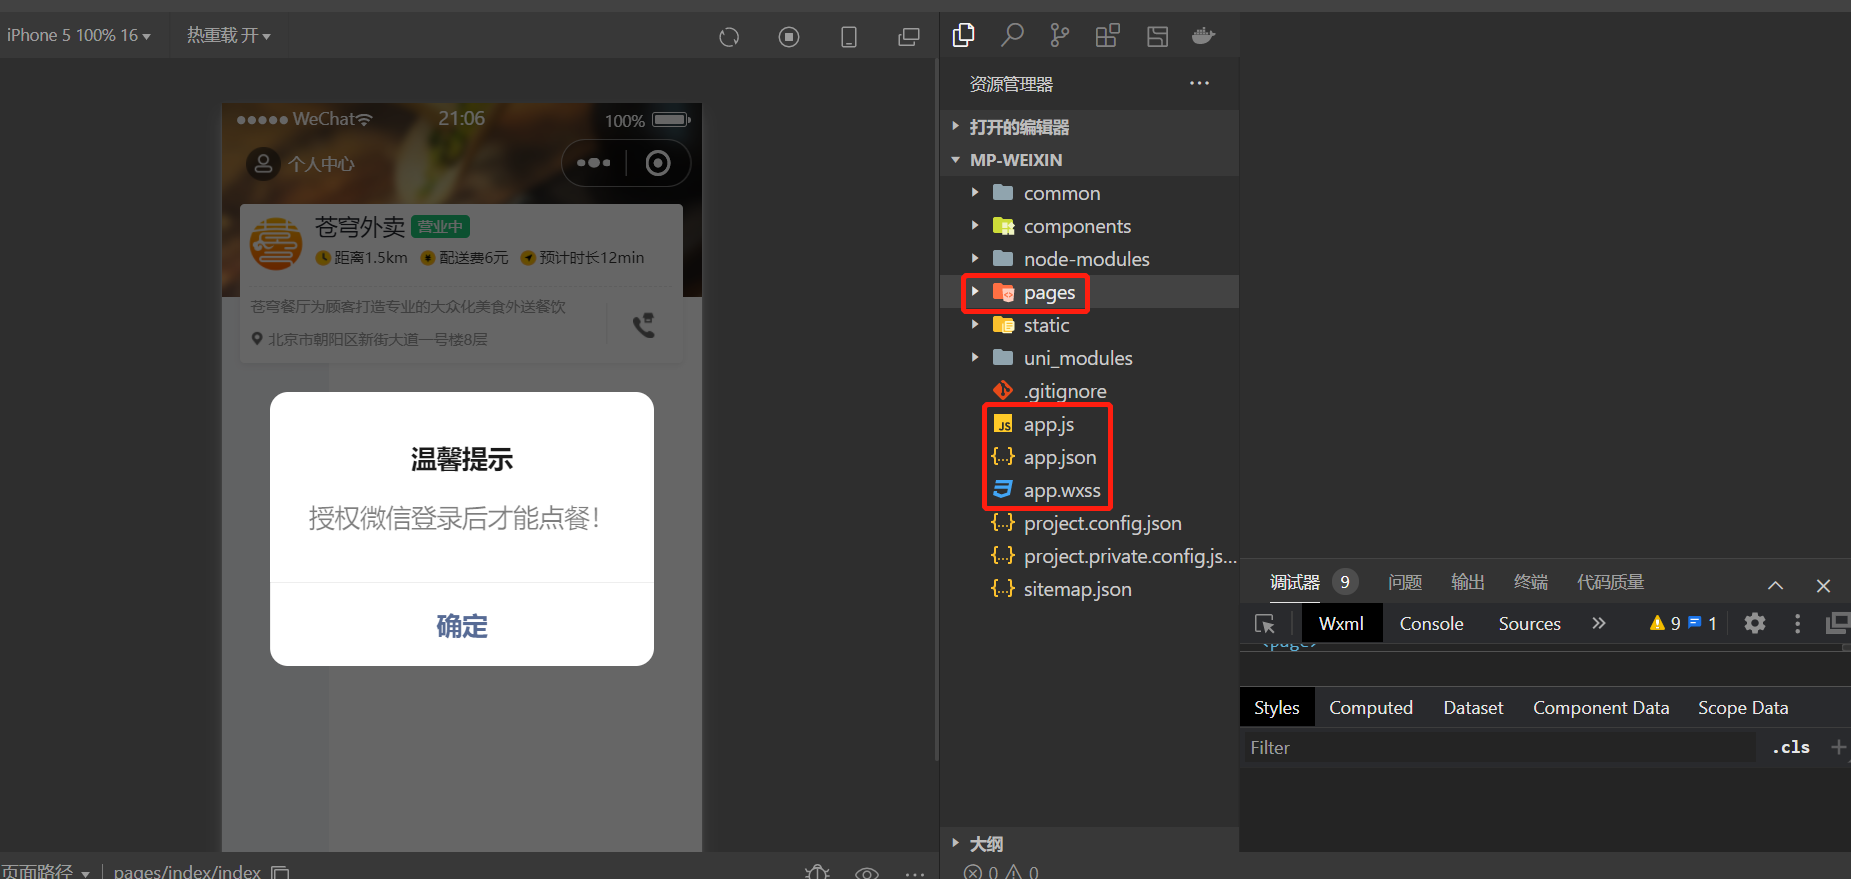 


**4). 修改配置**

因为小程序要请求后端服务，需要修改为自己后端服务的ip地址和端口号(默认不需要修改)

common-->vendor.js-->搜索(ctrl+f)-->baseUri

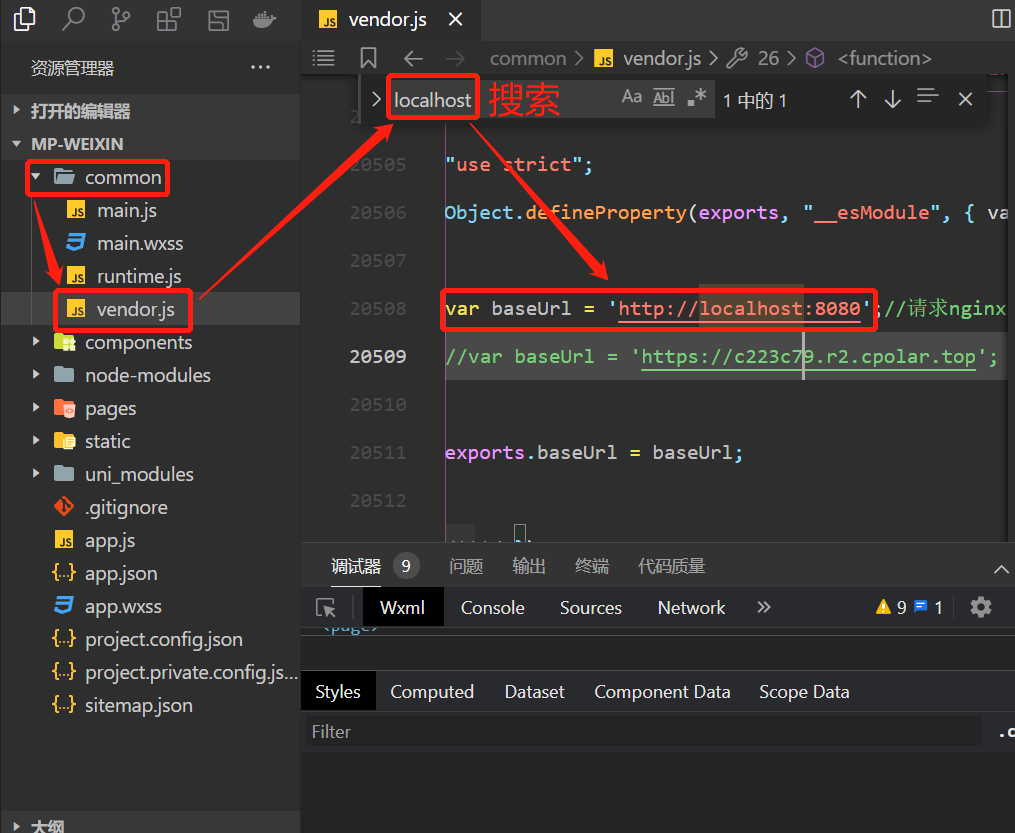


### 导入现有项目而不是重建页面（补充）

使用当天资料中的完整小程序目录，确认app.json和pages资源都存在。课程指出baseUri位于common/vendor.js；这是该资料产物的具体位置，不能推断所有项目都在相同文件配置地址。

若拿到的是源工程，应优先修改其源配置再构建；直接修改编译产物可能在下一次编译时被覆盖。核对baseUri是否已包含/user，避免拼成/user/user/user/login或遗漏路径。

登录前先验证第05章 `/user/shop/status`可访问；它成功只证明当前请求通路基本正常，不表示微信AppID、Secret或登录接口已正确。


### 3.2 微信登录流程

> **PPT对照：** 第41页。

微信登录：https://developers.weixin.qq.com/miniprogram/dev/framework/open-ability/login.html

**流程图：**

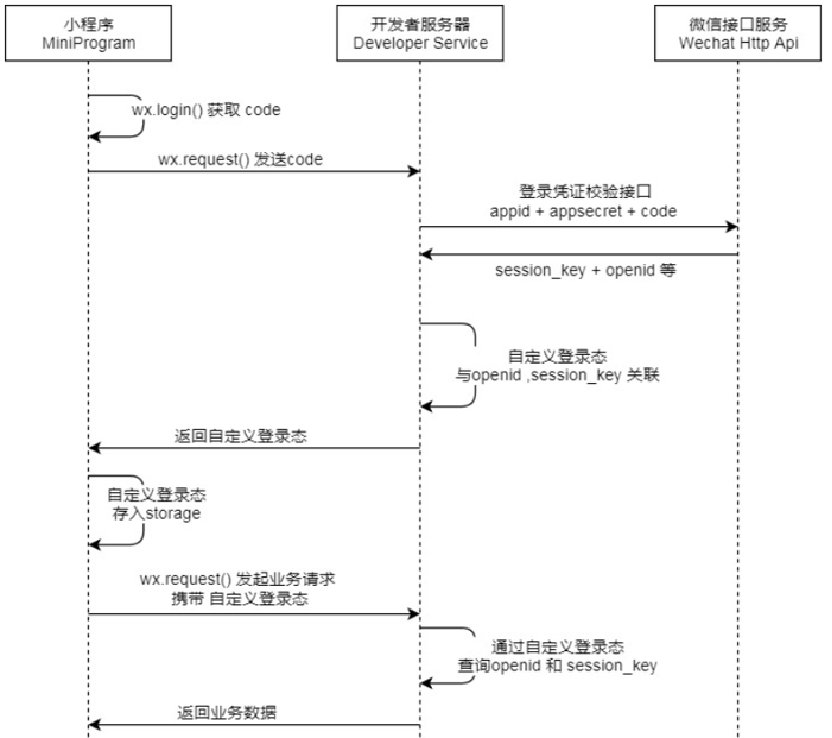 


**步骤分析：**

1. 小程序端，调用wx.login()获取code，就是授权码。
2. 小程序端，调用wx.request()发送请求并携带code，请求开发者服务器(自己编写的后端服务)。
3. 开发者服务端，通过HttpClient向微信接口服务发送请求，并携带appId+appsecret+code三个参数。
4. 开发者服务端，接收微信接口服务返回的数据，session_key+opendId等。opendId是微信用户的唯一标识。
5. 开发者服务端，自定义登录态，生成令牌(token)和openid等数据返回给小程序端，方便后绪请求身份校验。
6. 小程序端，收到自定义登录态，存储storage。
7. 小程序端，后绪通过wx.request()发起业务请求时，携带token。
8. 开发者服务端，收到请求后，通过携带的token，解析当前登录用户的id。
9. 开发者服务端，身份校验通过后，继续相关的业务逻辑处理，最终返回业务数据。


接下来，我们使用Postman进行测试。

**说明：**

1. 调用 [wx.login()](https://developers.weixin.qq.com/miniprogram/dev/api/open-api/login/wx.login.html) 获取 **临时登录凭证code** ，并回传到开发者服务器。
2. 调用 [auth.code2Session](https://developers.weixin.qq.com/miniprogram/dev/api-backend/open-api/login/auth.code2Session.html) 接口，换取 **用户唯一标识 OpenID** 、 用户在微信开放平台帐号下的**唯一标识UnionID**（若当前小程序已绑定到微信开放平台帐号） 和 **会话密钥 session_key**。

之后开发者服务器可以根据用户标识来生成自定义登录态，用于后续业务逻辑中前后端交互时识别用户身份。

**实现步骤：**

**1). 获取授权码**

点击确定按钮，获取授权码，每个授权码只能使用一次，每次测试，需重新获取。

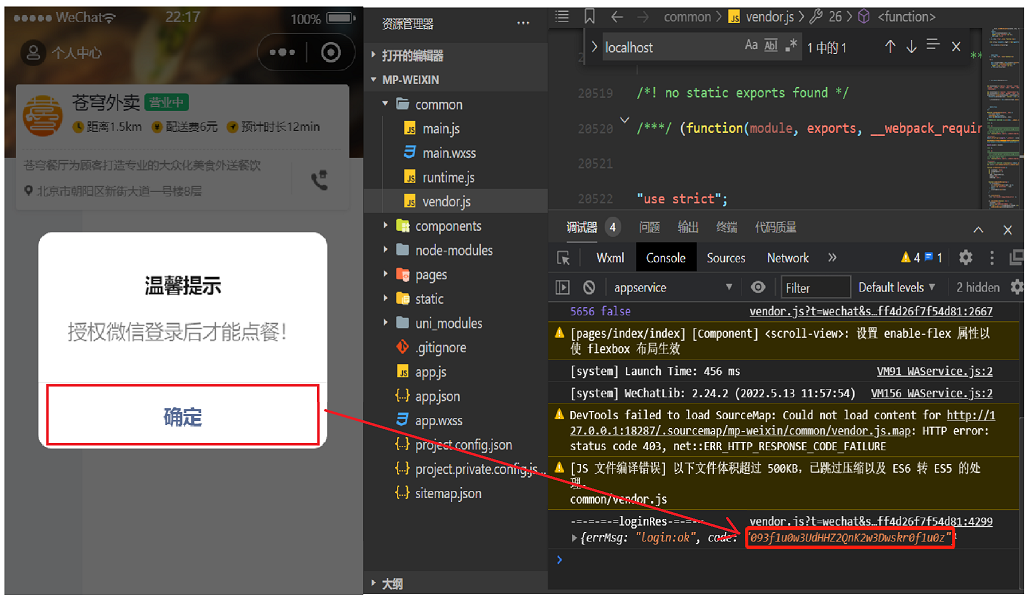 


**2). 明确请求接口**

请求方式、请求路径、请求参数

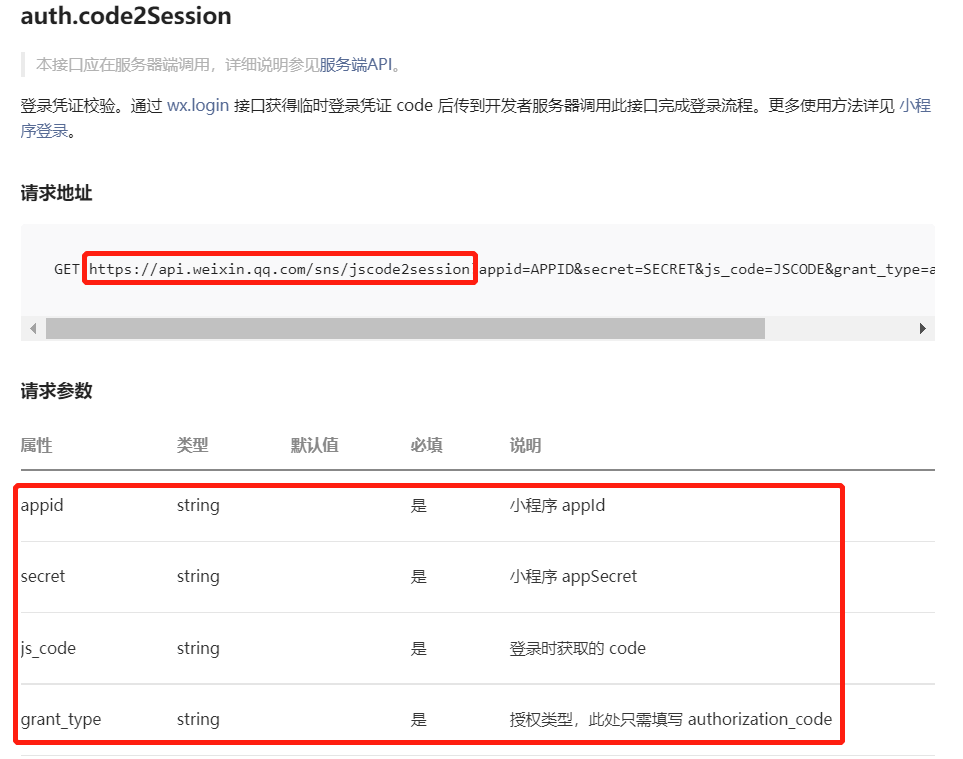 


**3). 发送请求**

获取session_key和openid

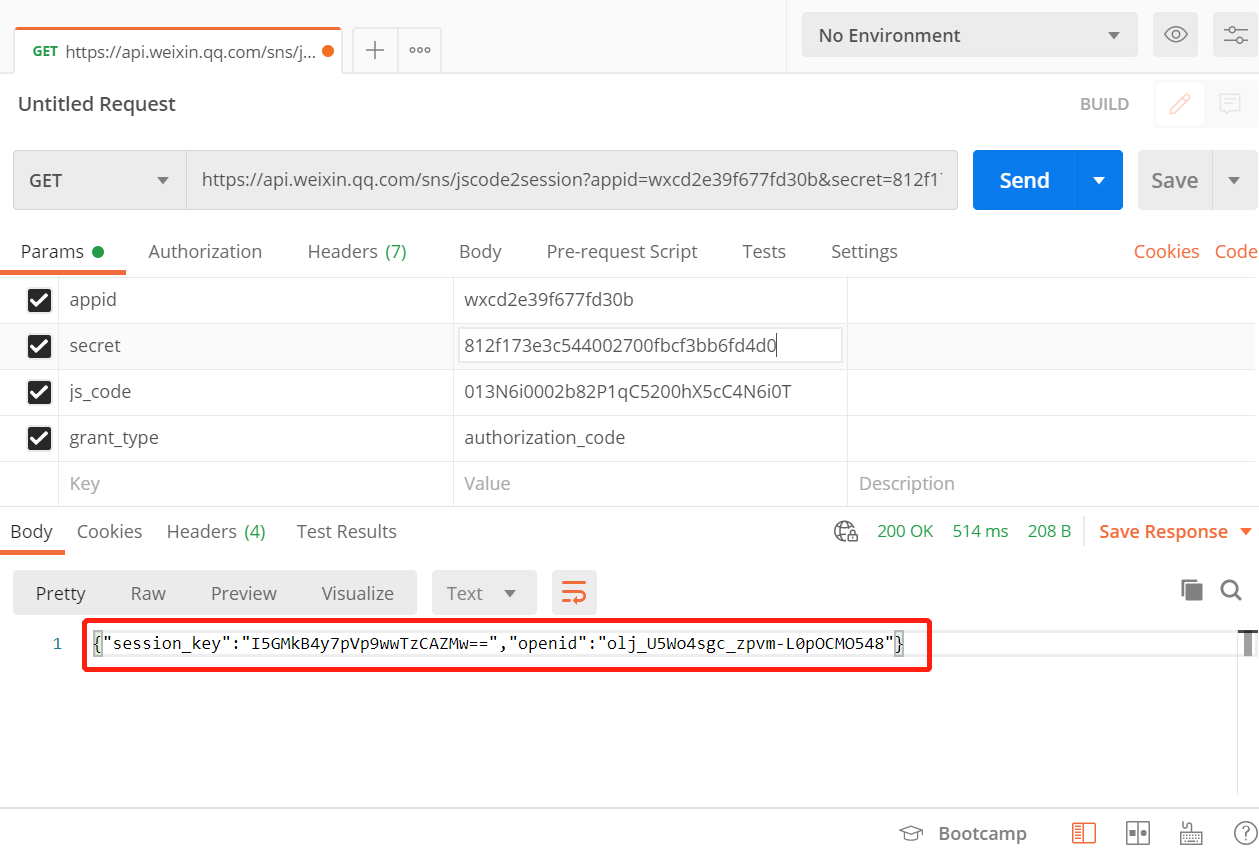 

若出现code been used错误提示，说明授权码已被使用过，请重新获取

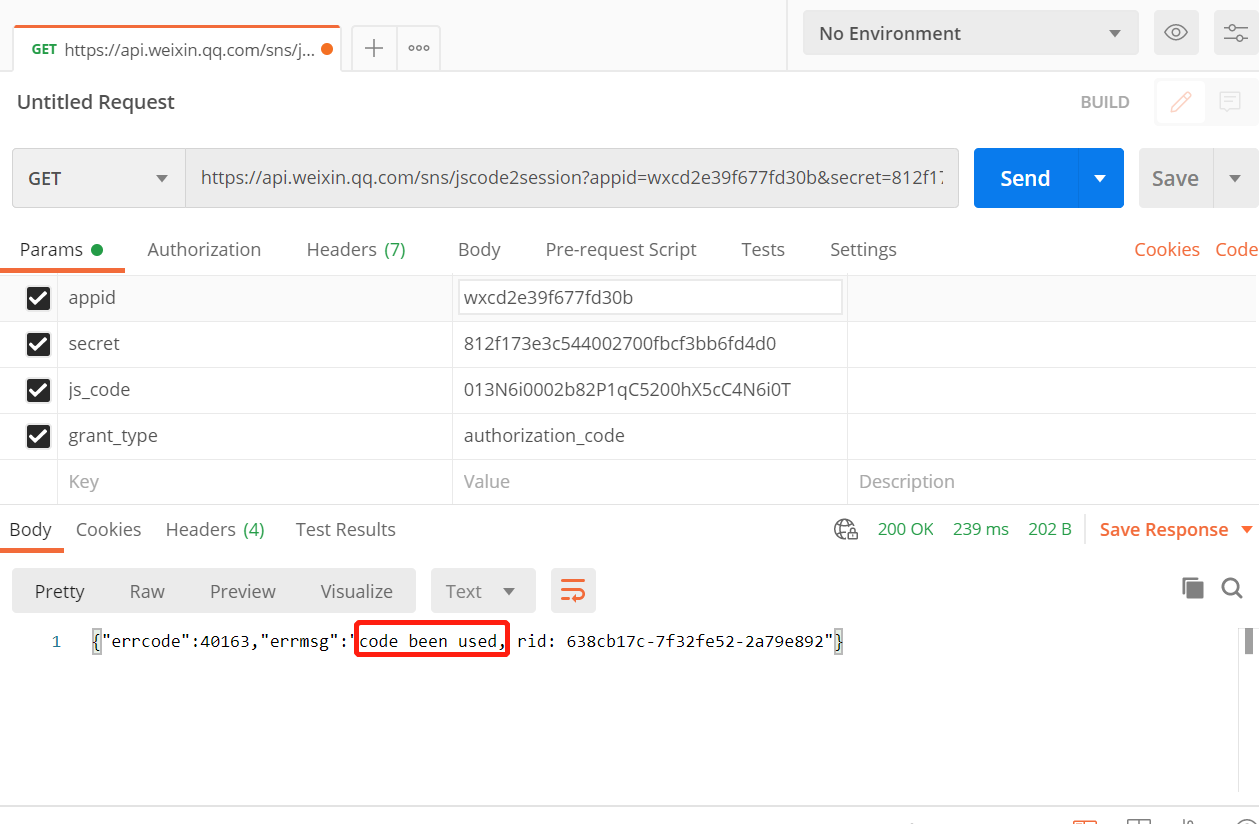


### code2Session中的身份和会话（补充与勘误）

openid在同一AppID范围内识别用户，不是全微信平台通用用户id。unionid只有满足微信开放平台相应条件时才可能返回，原文简化了条件；当前登录不要把unionid设为必填，也不能无条件依赖它跨应用关联账号。

code是短时、一次性的临时凭证。Postman拿它直接请求微信后，这个code已经被消费；再把同一个code发给自己的登录接口，会收到已使用或无效等错误。每次验证登录重新wx.login获取code，不复用截图中的值。

微信返回session_key不等于发给小程序一个业务JWT。我们的token写入数据库user.id，后续业务使用这个id识别账号；openid用于关联微信身份。原文中的opendId是拼写误差，应理解为openid。

AppSecret与session_key留在后端，不作为响应字段；日志也不打印完整微信响应、code或业务token。本章只需要openid完成身份关联，没用到session_key并不表示应该把它交给前端保存。


### 3.3 需求分析和设计

> **PPT对照：** 第43—45页。

#### 3.3.1 产品原型

用户进入到小程序的时候，微信授权登录之后才能点餐。需要获取当前微信用户的相关信息，比如昵称、头像等，这样才能够进入到小程序进行下单操作。是基于微信登录来实现小程序的登录功能，没有采用传统账户密码登录的方式。若第一次使用小程序来点餐，就是一个新用户，需要把这个新的用户保存到数据库当中完成自动注册。

**登录功能原型图：**

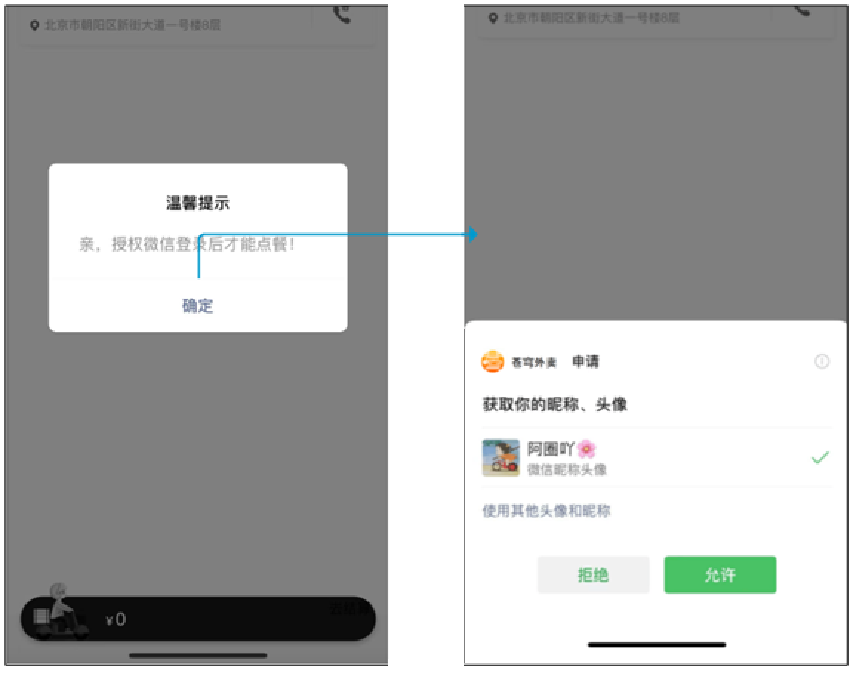 


**业务规则：**

- 基于微信登录实现小程序的登录功能
- 如果是新用户需要自动完成注册


#### 3.3.2 接口设计

通过微信登录的流程，如果要完成微信登录的话，最终就要获得微信用户的openid。在小程序端获取授权码后，向后端服务发送请求，并携带授权码，这样后端服务在收到授权码后，就可以去请求微信接口服务。最终，后端向小程序返回openid和token等数据。

基于上述的登录流程，就可以设计出该接口的**请求参数**和**返回数据**。

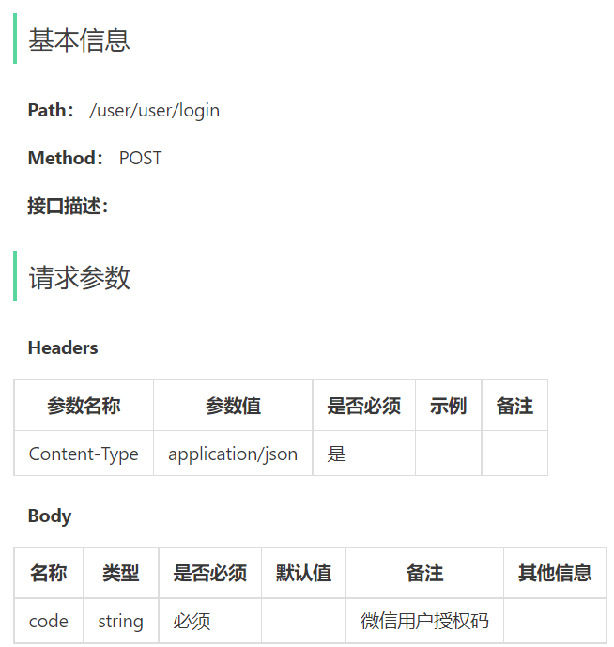 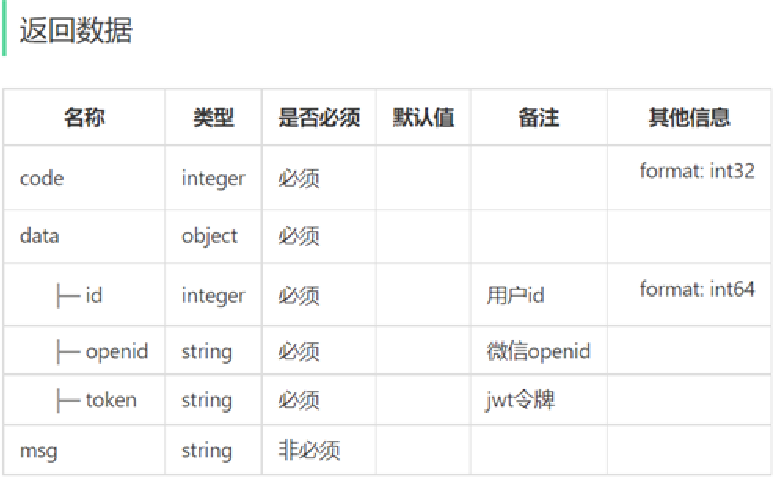

**说明：**请求路径/user/user/login,第一个user代表用户端，第二个user代表用户模块。


#### 3.3.3 表设计

当用户第一次使用小程序时，会完成自动注册，把用户信息存储到**user**表中。

| **字段名**  | **数据类型** | **说明**           | **备注** |
| ----------- | ------------ | ------------------ | -------- |
| id          | bigint       | 主键               | 自增     |
| openid      | varchar(45)  | 微信用户的唯一标识 |          |
| name        | varchar(32)  | 用户姓名           |          |
| phone       | varchar(11)  | 手机号             |          |
| sex         | varchar(2)   | 性别               |          |
| id_number   | varchar(18)  | 身份证号           |          |
| avatar      | varchar(500) | 微信用户头像路径   |          |
| create_time | datetime     | 注册时间           |          |

**说明：**手机号字段比较特殊，个人身份注册的小程序没有权限获取到微信用户的手机号。如果是以企业的资质
注册的小程序就能够拿到微信用户的手机号。


### 自动注册真正写了哪些字段（补充）

原DTO只有code，首次注册构造User时只设置openid与createTime。user表有name、avatar、phone等字段，不表示登录后它们都会自动填好；不需要自行编造昵称、手机号或身份证号。

user.id是数据库主键，返回给业务token；openid是微信标识，两者不是同一个字段。UserLoginVO只暴露id、openid、token，避免直接把整个用户实体作为登录响应。

“查询不存在再插入”在并发请求下可能同时发生。检查初始化数据库是否对openid建立了唯一约束；单AppID模型可按openid唯一，多AppID模型通常还需要AppID维度。唯一约束与冲突后的查询/错误处理应配合，单加事务不能替代唯一性保证。

user表没有完整的员工/菜品四项审计字段，不应为其insert方法直接套用第03章的单实体四字段AutoFill；原实现单独设置createTime。


### 3.4 代码开发

> **PPT对照：** 第47—60页。

#### 3.4.1 定义相关配置

**配置微信登录所需配置项：**

application-dev.yml

```yaml
sky:
  wechat:
    appid: <填写你的小程序AppID>
    secret: <填写你的小程序AppSecret>
```

application.yml

```yaml
sky:
  wechat:
    appid: ${sky.wechat.appid}
    secret: ${sky.wechat.secret}
```

**配置为微信用户生成jwt令牌时使用的配置项：**

application.yml

```yaml
sky:
  jwt:
    # 设置jwt签名加密时使用的秘钥
    admin-secret-key: itcast
    # 设置jwt过期时间
    admin-ttl: 7200000
    # 设置前端传递过来的令牌名称
    admin-token-name: token
    user-secret-key: itheima
    user-ttl: 7200000
    user-token-name: authentication
```


#### 3.4.2 DTO设计

**根据传入参数设计DTO类：**

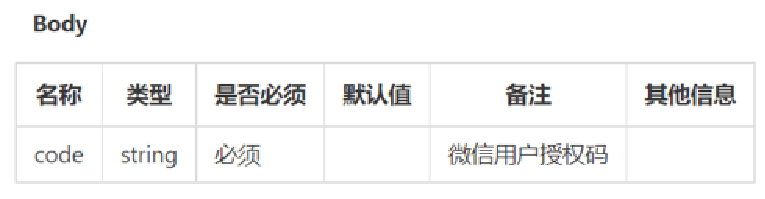 

在sky-pojo模块，UserLoginDTO.java已定义

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

/**
 * C端用户登录
 */
@Data
public class UserLoginDTO implements Serializable {

    private String code;

}
```


#### 3.4.3 VO设计

**根据返回数据设计VO类：**

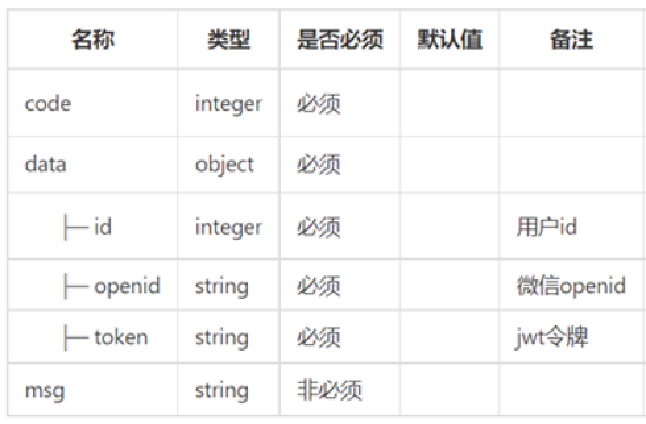 

在sky-pojo模块，UserLoginVO.java已定义

```java
package com.sky.vo;

import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;

import java.io.Serializable;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class UserLoginVO implements Serializable {

    private Long id;
    private String openid;
    private String token;

}
```


#### 3.4.4 Controller层

**根据接口定义创建UserController的login方法：**

```java
package com.sky.controller.user;

import com.sky.constant.JwtClaimsConstant;
import com.sky.dto.UserLoginDTO;
import com.sky.entity.User;
import com.sky.properties.JwtProperties;
import com.sky.result.Result;
import com.sky.service.UserService;
import com.sky.utils.JwtUtil;
import com.sky.vo.UserLoginVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RequestBody;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.util.HashMap;
import java.util.Map;

@RestController
@RequestMapping("/user/user")
@Api(tags = "C端用户相关接口")
@Slf4j
public class UserController {

    @Autowired
    private UserService userService;
    @Autowired
    private JwtProperties jwtProperties;

    /**
     * 微信登录
     * @param userLoginDTO
     * @return
     */
    @PostMapping("/login")
    @ApiOperation("微信登录")
    public Result<UserLoginVO> login(@RequestBody UserLoginDTO userLoginDTO){
        log.info("微信用户登录：{}",userLoginDTO.getCode());

        //微信登录
        User user = userService.wxLogin(userLoginDTO);//后绪步骤实现

        //为微信用户生成jwt令牌
        Map<String, Object> claims = new HashMap<>();
        claims.put(JwtClaimsConstant.USER_ID,user.getId());
        String token = JwtUtil.createJWT(jwtProperties.getUserSecretKey(), jwtProperties.getUserTtl(), claims);

        UserLoginVO userLoginVO = UserLoginVO.builder()
                .id(user.getId())
                .openid(user.getOpenid())
                .token(token)
                .build();
        return Result.success(userLoginVO);
    }
}
```

其中，JwtClaimsConstant.USER_ID常量已定义。


#### 3.4.5 Service层接口

**创建UserService接口：**

```java
package com.sky.service;

import com.sky.dto.UserLoginDTO;
import com.sky.entity.User;

public interface UserService {

    /**
     * 微信登录
     * @param userLoginDTO
     * @return
     */
    User wxLogin(UserLoginDTO userLoginDTO);
}
```


#### 3.4.6 Service层实现类

**创建UserServiceImpl实现类：**实现获取微信用户的openid和微信登录功能

```java
package com.sky.service.impl;

import com.alibaba.fastjson.JSON;
import com.alibaba.fastjson.JSONObject;
import com.sky.constant.MessageConstant;
import com.sky.dto.UserLoginDTO;
import com.sky.entity.User;
import com.sky.exception.LoginFailedException;
import com.sky.mapper.UserMapper;
import com.sky.properties.WeChatProperties;
import com.sky.service.UserService;
import com.sky.utils.HttpClientUtil;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;

import java.time.LocalDateTime;
import java.util.HashMap;
import java.util.Map;

@Service
@Slf4j
public class UserServiceImpl implements UserService {

    //微信服务接口地址
    public static final String WX_LOGIN = "https://api.weixin.qq.com/sns/jscode2session";

    @Autowired
    private WeChatProperties weChatProperties;
    @Autowired
    private UserMapper userMapper;

    /**
     * 微信登录
     * @param userLoginDTO
     * @return
     */
    public User wxLogin(UserLoginDTO userLoginDTO) {
        String openid = getOpenid(userLoginDTO.getCode());

        //判断openid是否为空，如果为空表示登录失败，抛出业务异常
        if(openid == null){
            throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
        }

        //判断当前用户是否为新用户
        User user = userMapper.getByOpenid(openid);

        //如果是新用户，自动完成注册
        if(user == null){
            user = User.builder()
                    .openid(openid)
                    .createTime(LocalDateTime.now())
                    .build();
            userMapper.insert(user);//后绪步骤实现
        }

        //返回这个用户对象
        return user;
    }

    /**
     * 调用微信接口服务，获取微信用户的openid
     * @param code
     * @return
     */
    private String getOpenid(String code){
        //调用微信接口服务，获得当前微信用户的openid
        Map<String, String> map = new HashMap<>();
        map.put("appid",weChatProperties.getAppid());
        map.put("secret",weChatProperties.getSecret());
        map.put("js_code",code);
        map.put("grant_type","authorization_code");
        String json = HttpClientUtil.doGet(WX_LOGIN, map);

        JSONObject jsonObject = JSON.parseObject(json);
        String openid = jsonObject.getString("openid");
        return openid;
    }
}
```


#### 3.4.7 Mapper层

**创建UserMapper接口：**

```java
package com.sky.mapper;

import com.sky.entity.User;
import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Select;

@Mapper
public interface UserMapper {

    /**
     * 根据openid查询用户
     * @param openid
     * @return
     */
    @Select("select * from user where openid = #{openid}")
    User getByOpenid(String openid);

    /**
     * 插入数据
     * @param user
     */
    void insert(User user);
}
```

**创建UserMapper.xml映射文件：**

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.UserMapper">

    <insert id="insert" useGeneratedKeys="true" keyProperty="id">
        insert into user (openid, name, phone, sex, id_number, avatar, create_time)
        values (#{openid}, #{name}, #{phone}, #{sex}, #{idNumber}, #{avatar}, #{createTime})
    </insert>

</mapper>
```


#### 3.4.8 编写拦截器

**编写拦截器JwtTokenUserInterceptor：**统一拦截用户端发送的请求并进行jwt校验

```java
package com.sky.interceptor;

import com.sky.constant.JwtClaimsConstant;
import com.sky.context.BaseContext;
import com.sky.properties.JwtProperties;
import com.sky.utils.JwtUtil;
import io.jsonwebtoken.Claims;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Component;
import org.springframework.web.method.HandlerMethod;
import org.springframework.web.servlet.HandlerInterceptor;

import javax.servlet.http.HttpServletRequest;
import javax.servlet.http.HttpServletResponse;

/**
 * jwt令牌校验的拦截器
 */
@Component
@Slf4j
public class JwtTokenUserInterceptor implements HandlerInterceptor {

    @Autowired
    private JwtProperties jwtProperties;

    /**
     * 校验jwt
     *
     * @param request
     * @param response
     * @param handler
     * @return
     * @throws Exception
     */
    public boolean preHandle(HttpServletRequest request, HttpServletResponse response, Object handler) throws Exception {
        //判断当前拦截到的是Controller的方法还是其他资源
        if (!(handler instanceof HandlerMethod)) {
            //当前拦截到的不是动态方法，直接放行
            return true;
        }

        //1、从请求头中获取令牌
        String token = request.getHeader(jwtProperties.getUserTokenName());

        //2、校验令牌
        try {
            log.info("jwt校验:{}", token);
            Claims claims = JwtUtil.parseJWT(jwtProperties.getUserSecretKey(), token);
            Long userId = Long.valueOf(claims.get(JwtClaimsConstant.USER_ID).toString());
            log.info("当前用户的id：", userId);
            BaseContext.setCurrentId(userId);
            //3、通过，放行
            return true;
        } catch (Exception ex) {
            //4、不通过，响应401状态码
            response.setStatus(401);
            return false;
        }
    }
}
```

**在WebMvcConfiguration配置类中注册拦截器：**

```java
	@Autowired
    private JwtTokenUserInterceptor jwtTokenUserInterceptor;
	/**
     * 注册自定义拦截器
     * @param registry
     */
    protected void addInterceptors(InterceptorRegistry registry) {
        log.info("开始注册自定义拦截器...");
        //.........

        registry.addInterceptor(jwtTokenUserInterceptor)
                .addPathPatterns("/user/**")
                .excludePathPatterns("/user/user/login")
                .excludePathPatterns("/user/shop/status");
    }
```


### 配置、错误响应与用户鉴权（补充与勘误）

#### 1. 三套配置分清用途

| 配置 | 用途 | 存放位置 |
| --- | --- | --- |
| wechat.appid / secret | 后端请求微信code2Session | 后端受控配置 |
| jwt.admin-* | 员工登录、管理端验签 | 后端，沿用员工配置 |
| jwt.user-* | 用户登录、用户端验签 | 后端，单独使用用户配置 |

原user-token-name为authentication，而管理端token-name为token。登录响应字段仍叫token，后续请求头名称由user-token-name决定；不能因为返回字段叫token，就向用户端发送错误的header。

user-ttl=7200000按课程JwtUtil的毫秒参数表示2小时，不是7200000秒。签名密钥应使用实际环境的合适随机密钥，不沿用原itcast、itheima演示字符串，也不放到小程序代码中。令牌有效期与微信code有效期是不同概念。

微信配置可使用环境变量提供；如果采用此方案，放入实际启用的配置文件，避免保留另一套同名定义造成覆盖或自引用：

```yaml
sky:
  wechat:
    appid: ${WECHAT_APP_ID}
    secret: ${WECHAT_APP_SECRET}
```

原代码依赖初始工程的WeChatProperties、JwtProperties、HttpClientUtil、JwtUtil、User实体和LoginFailedException。先确认这些类存在。WeChatProperties需能绑定sky.wechat的appid/secret；JwtProperties需有userSecretKey、userTtl、userTokenName及相应getter，不能只保留员工字段。

#### 2. 微信接口可能返回错误JSON

原getOpenid直接parseObject后取openid，仅在调用处判openid==null。它没有处理空响应、非JSON、微信errcode或空字符串openid；HttpClientUtil是否设置超时、是否吞异常，也应检查初始工具类。

可以在已有UserServiceImpl中替换getOpenid，并在wxLogin一开始校验DTO和code：

```java
// 放在wxLogin方法开头，随后沿用查询用户、自动注册的流程。
if (userLoginDTO == null
        || !org.springframework.util.StringUtils.hasText(userLoginDTO.getCode())) {
    throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
}
```

```java
private String getOpenid(String code) {
    Map<String, String> params = new HashMap<>();
    params.put("appid", weChatProperties.getAppid());
    params.put("secret", weChatProperties.getSecret());
    params.put("js_code", code);
    params.put("grant_type", "authorization_code");

    try {
        String json = HttpClientUtil.doGet(WX_LOGIN, params);
        if (!org.springframework.util.StringUtils.hasText(json)) {
            throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
        }
        JSONObject body = JSON.parseObject(json);
        if (body == null) {
            throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
        }
        Integer errcode = body.getInteger("errcode");
        if (errcode != null && errcode != 0) {
            // 只记录错误码，不记录带session_key的完整响应或请求参数。
            log.warn("微信登录失败，errcode={}", errcode);
            throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
        }
        String openid = body.getString("openid");
        if (!org.springframework.util.StringUtils.hasText(openid)) {
            throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
        }
        return openid;
    } catch (LoginFailedException e) {
        throw e;
    } catch (RuntimeException e) {
        // 对外统一失败；需要诊断时记录不包含凭据的错误分类。
        throw new LoginFailedException(MessageConstant.LOGIN_FAILED);
    }
}
```

此示例兼容原HttpClientUtil.doGet返回String的约定，不替代工具类的HTTP状态、超时与资源处理。调用微信失败时不注册用户、不签token；不要自动重试同一个已消费code。微信失败原因可按受控错误码分类提示，避免把包含凭据的原始响应直接返回。

PPT第55页的代码有中文引号和完整微信响应日志，复制Java时改用英文引号，并移除完整响应日志。原Controller打印code、拦截器打印token，也应改成仅记录登录事件或必要的非敏感标识。

#### 3. 注册主键回填与并发

UserMapper.xml的 `useGeneratedKeys="true" keyProperty="id"`必须保留。新用户插入后，user.id需要有值，Controller才能放进JWT声明并返回VO。

回访用户沿用原id，不重复insert。并发首次注册要由数据库唯一约束保证，再处理重复键冲突并查询已存在账号；原讲义没有完整处理这条分支。若有多个AppID，查询条件和唯一键也要包含所属应用，不能混用不同应用的openid。

Mapper参数名可显式写 `@Param("openid")`，XML namespace应为com.sky.mapper.UserMapper。注册时间由后端设置，不直接信任客户端。

#### 4. 用户拦截器清理ThreadLocal

原日志 `log.info("当前用户的id：", userId)`少了{}，不会按预期显示id，可改成：

```java
log.debug("当前用户的id：{}", userId);
```

原拦截器设置BaseContext后未清理。用户id是user表主键，员工id是employee表主键，两者即使数字相同也不能互换；线程复用时尤其不能遗留上一请求身份。

在原preHandle进入时先清理，在验签失败catch内也清理，并加afterCompletion：

```java
// preHandle开头，放在原业务逻辑之前。
BaseContext.removeCurrentId();

// 原验签失败catch分支中，设置401并return false之前。
BaseContext.removeCurrentId();

// 放在JwtTokenUserInterceptor类内，与preHandle并列。
@Override
public void afterCompletion(HttpServletRequest request,
        HttpServletResponse response, Object handler, Exception ex) {
    BaseContext.removeCurrentId();
}
```

这是三个插入位置，不是独立完整方法。若初始BaseContext缺少removeCurrentId，给它补一个调用现有ThreadLocal.remove()的静态方法。preHandle返回false时不能只依赖afterCompletion清理；异步任务也不能假定自动继承请求线程的身份。

验签前检查token非空，验签后检查userId声明存在并为有效值；过期、错误签名、缺少声明均拒绝。原代码返回HTTP 401，小程序需要清除失效业务token并重新wx.login，不能靠openid自行恢复认证。

#### 5. 注册用户拦截器时保留管理端配置

原addInterceptors里的省略号表示已有代码，不表示删掉员工拦截器。保留/admin规则，再增加/user规则；登录接口不需要已有用户token，店铺状态按原约定公开，商品浏览需要用户token。

路径排除不会自动配置其他接口权限。原import使用javax.servlet，属于原工程API栈；迁移到使用jakarta.servlet的版本时需整体核对依赖，不混用两套包。

#### 小程序请求token示意

登录成功后，示例用自定义storage key“userToken”保存返回token；实际导入前端若用其他storage key，统一按它的请求封装约定，不强行改名。后续请求可写：

```javascript
wx.request({
  url: baseUri + '/user/dish/list', // 此处baseUri约定仅包含协议、地址与端口
  method: 'GET',
  data: { categoryId: selectedCategoryId },
  header: { authentication: wx.getStorageSync('userToken') },
  success: (res) => {
    if (res.statusCode === 401) {
      wx.removeStorageSync('userToken')
      // 按项目登录流程获取新code，再登录；不重用旧code。
      return
    }
    if (res.statusCode !== 200 || !res.data || res.data.code !== 1) {
      // 按项目方式显示错误，不直接读取空的业务data。
      return
    }
    this.setData({ dishes: res.data.data })
  },
  fail: () => {
    // 网络失败与业务失败分别处理。
  }
})
```

示例放在已有Page方法里，并由外层提供baseUri和selectedCategoryId；登录接口本身不需要authentication。token能校验身份，但业务访问仍需校验该用户能否操作目标数据。


### 3.5 功能测试

> **PPT对照：** 第62页。

重新编译小程序，进行登录，获取到openid和token数据

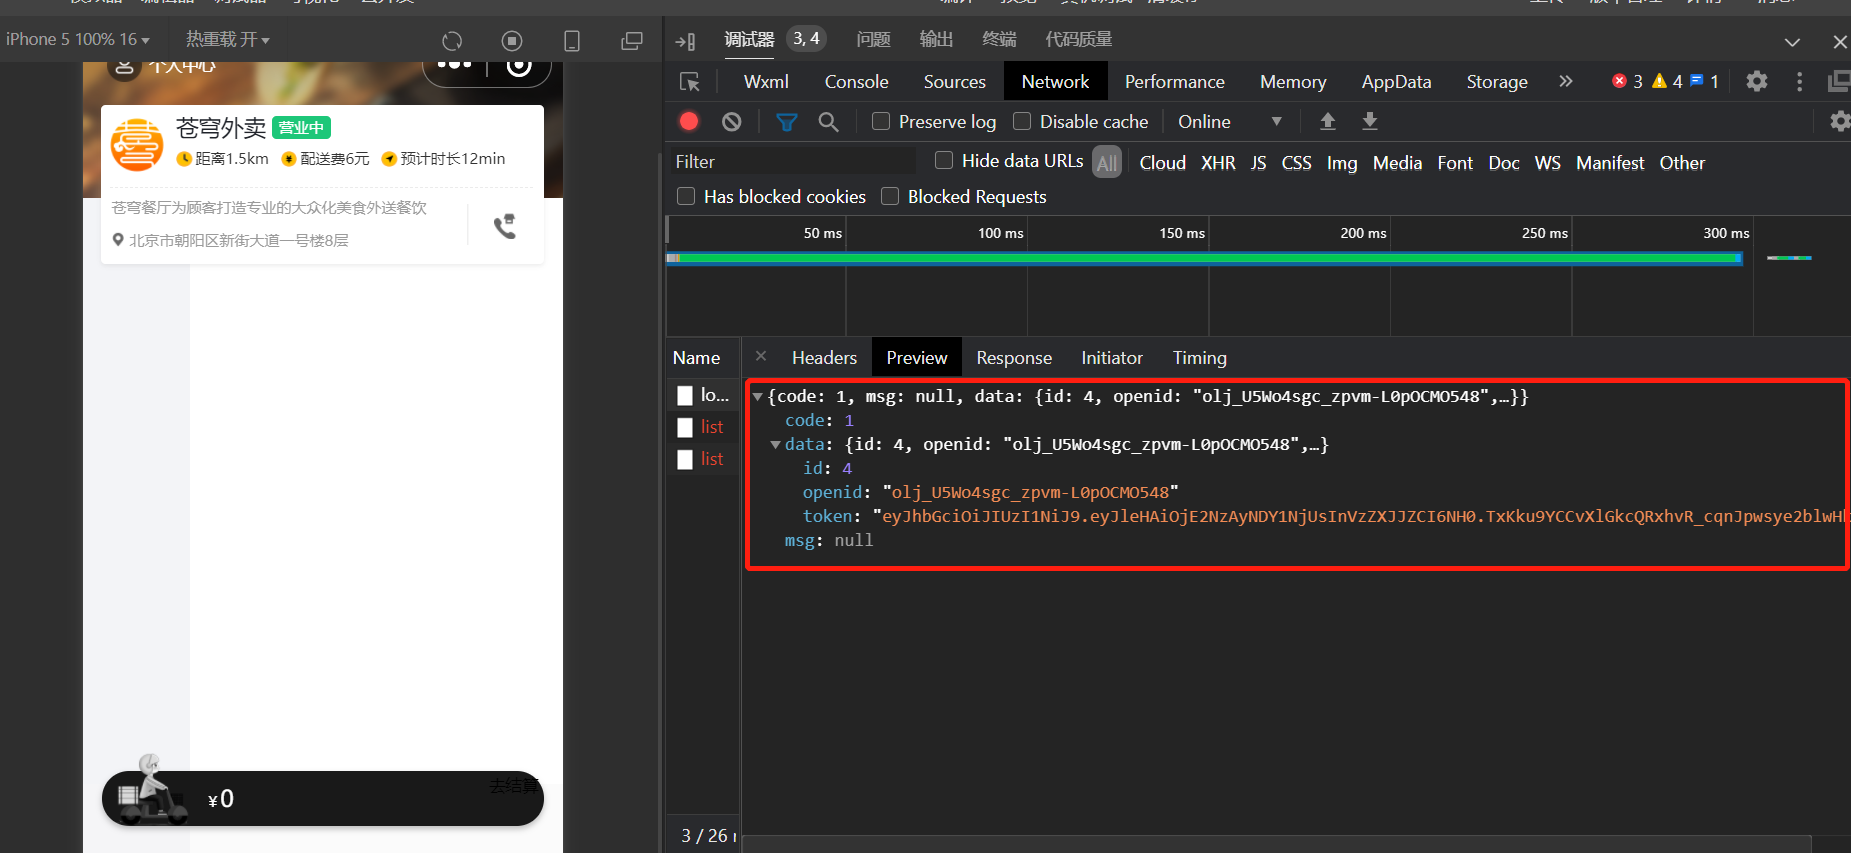 

查看后台日志

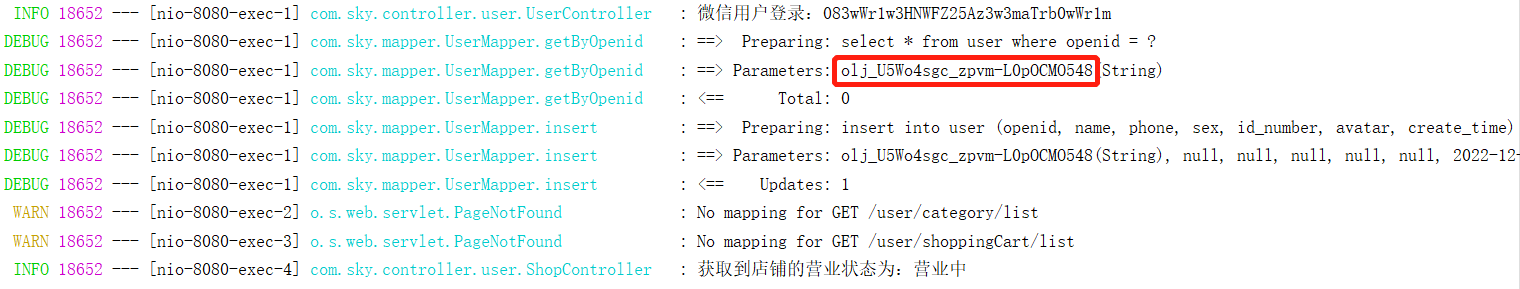  

查看数据库user表，第一次登录，会自动注册

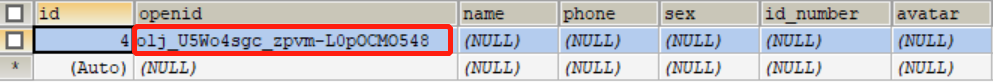


### 登录验收必须用新code（补充）

| 场景 | 预期 |
| --- | --- |
| 新用户第一次有效登录 | user新增一条，openid正确，id回填，返回token |
| 同一用户用新code再次登录 | 复用原id，不重复注册，签发本次token |
| code缺失、空串、过期或复用 | 登录失败，不插入用户、不签token |
| AppID与Secret不对应 | 微信调用失败，返回清晰业务错误 |
| 网络超时或非预期微信响应 | 失败结束，不发生空指针或空openid注册 |
| 用户token访问商品浏览 | 验签通过，BaseContext是对应user.id |
| 无token、过期token、错误签名 | HTTP 401，受保护业务不执行 |
| 管理员token访问用户端 | 按独立签名与用户声明规则拒绝 |
| 请求完成或拦截失败 | 当前线程身份被清理 |

数据库核对注册条数和id；日志不输出code、token、AppSecret或session_key。测试两个用户连续登录与查询，确认不同身份不会因线程复用串到下一请求。

联调时先检查真实请求里的登录路径、AppID、后端地址、响应体和authentication请求头，再检查UI。获取到头像昵称不是登录成功的验收证据。


## 4. 导入商品浏览功能代码

> **PPT对照：** 第64—74页。


### 4.1 需求分析和设计

> **PPT对照：** 第65—70页。

#### 4.1.1 产品原型

用户登录成功后跳转到系统首页，在首页需要根据分类来展示菜品和套餐。如果菜品设置了口味信息，需要展示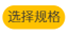按钮，否则显示按钮。

         **菜品列表效果图**                                                   **菜品口味效果图**

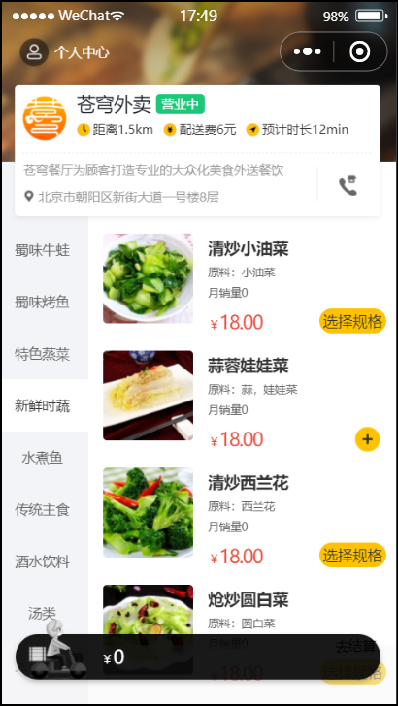                               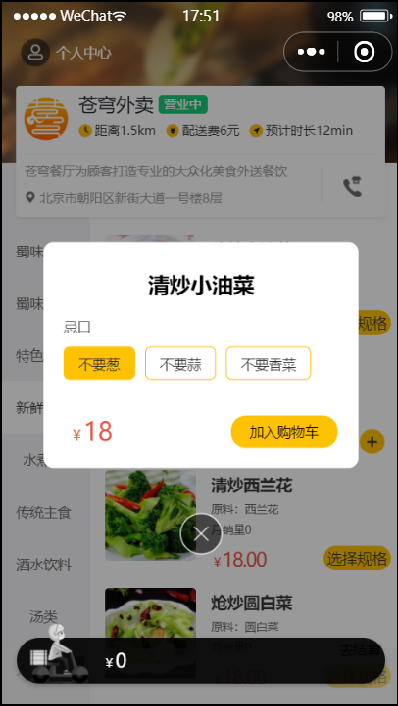 

         **套餐列表效果图**                                                   **套餐详情效果图**

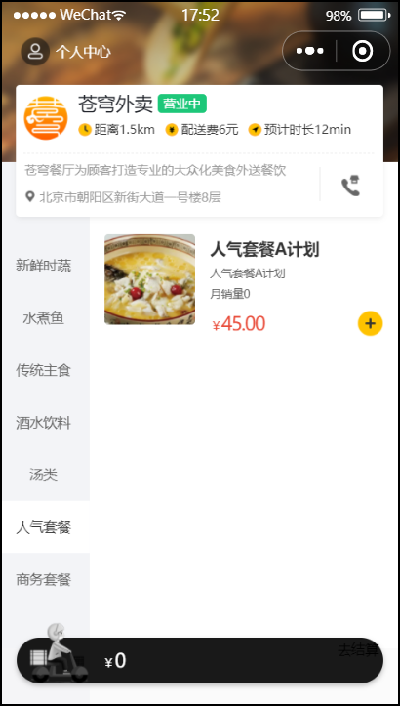                               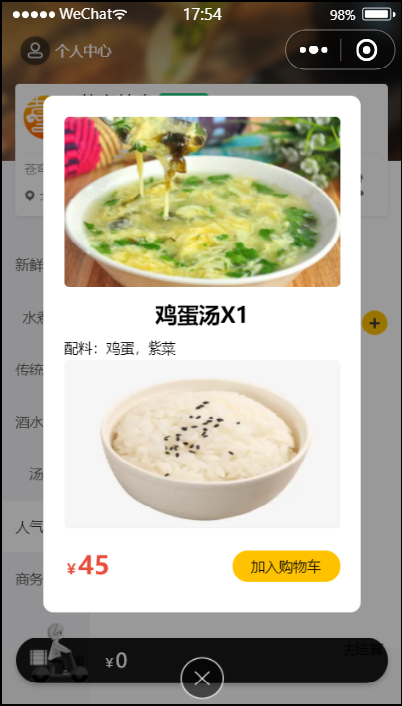 


#### 4.1.2 接口设计

根据上述原型图先**粗粒度**设计接口，共包含4个接口。

**接口设计：**

- 查询分类
- 根据分类id查询菜品
- 根据分类id查询套餐
- 根据套餐id查询包含的菜品


接下来**细粒度**分析每个接口，明确每个接口的请求方式、请求路径、传入参数和返回值。

**1). 查询分类**

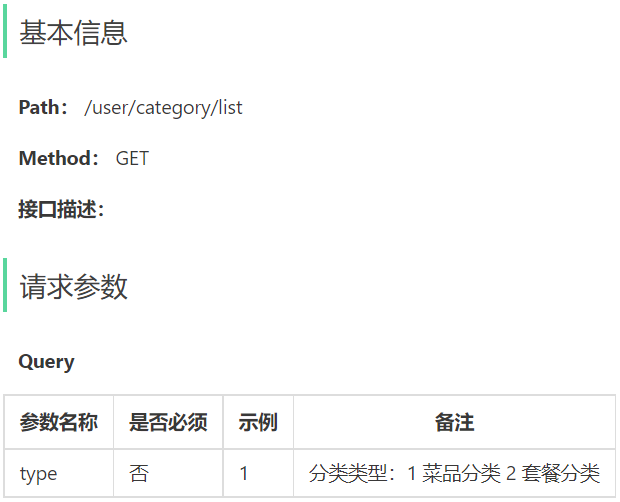 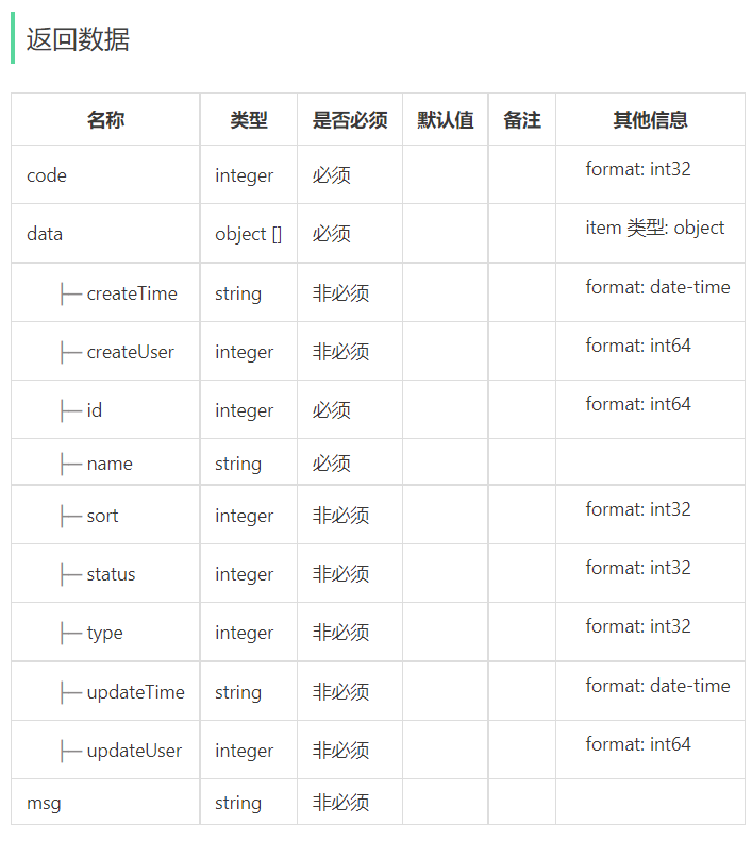


**2). 根据分类id查询菜品**

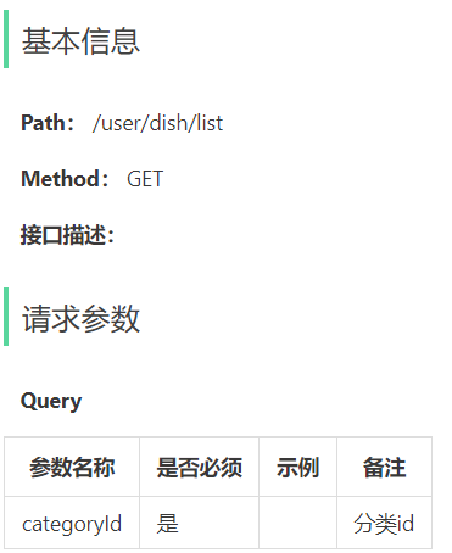 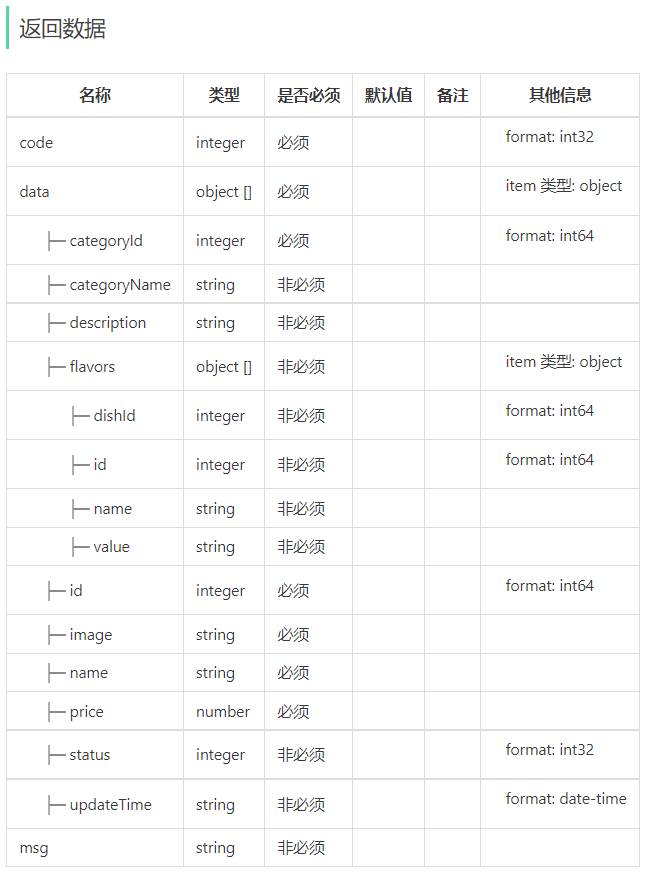


**3). 根据分类id查询套餐**

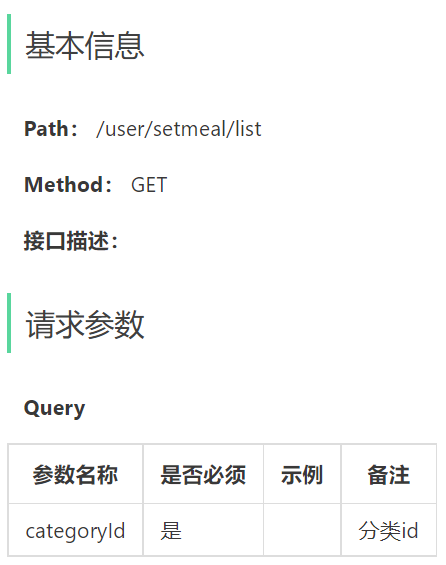 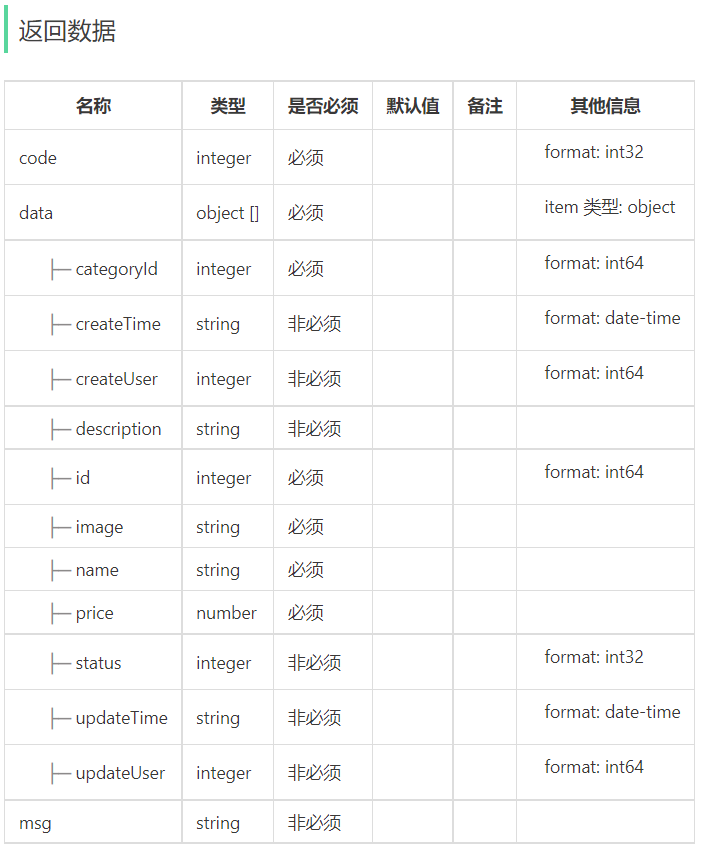


**4). 根据套餐id查询包含的菜品**

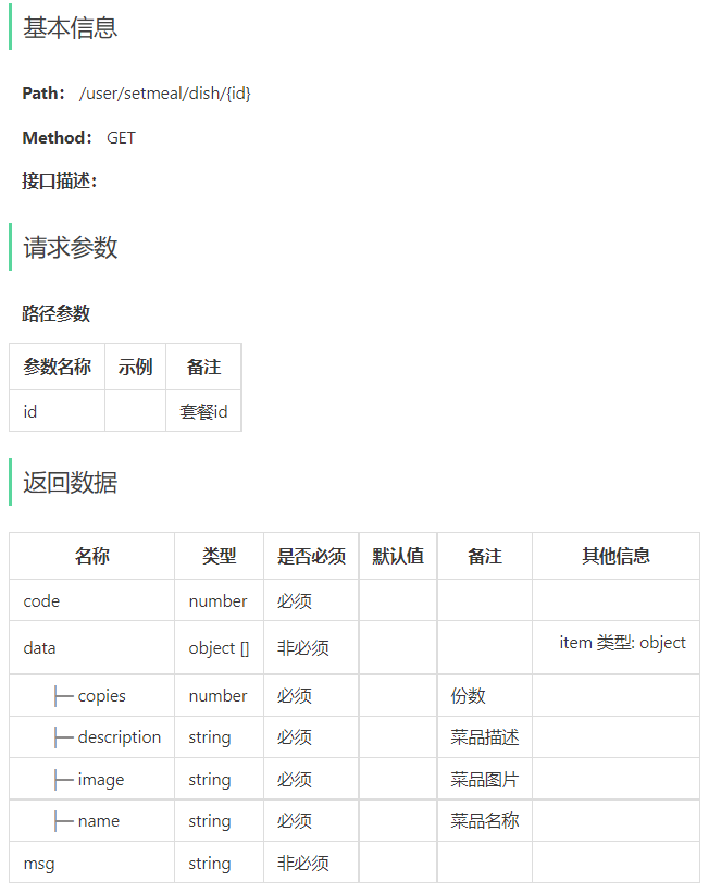


### 商品展示规则与数据来源（补充）

| 页面内容 | 接口数据与规则 |
| --- | --- |
| 菜品或套餐分类 | CategoryService.list；沿用启用分类、type和sort规则 |
| 分类内菜品 | categoryId筛选、强制status=1，转换成DishVO |
| 菜品口味 | dish_flavor记录；有口味显示选择入口 |
| 分类内套餐 | categoryId筛选、强制status=1 |
| 套餐明细 | setmeal_dish的name、copies，关联dish的image、description |

商品list不是管理端分页接口，不返回PageResult；当前实现也没有加入Redis商品缓存。页面“选规格”或加号只是展示与交互入口，本章没有实现购物车写入或下单。

套餐明细里的sd.name来自关联表保存的名称，图片和描述来自当前dish表；两者可能具有不同更新时间。LEFT JOIN会保留关联行，即使菜品被意外删除，图片与描述也可能为null，所以前面套餐关联保护仍有意义。


### 4.2 代码导入

> **PPT对照：** 第72页，详细实现由讲义提供。

导入资料中的商品浏览功能代码即可

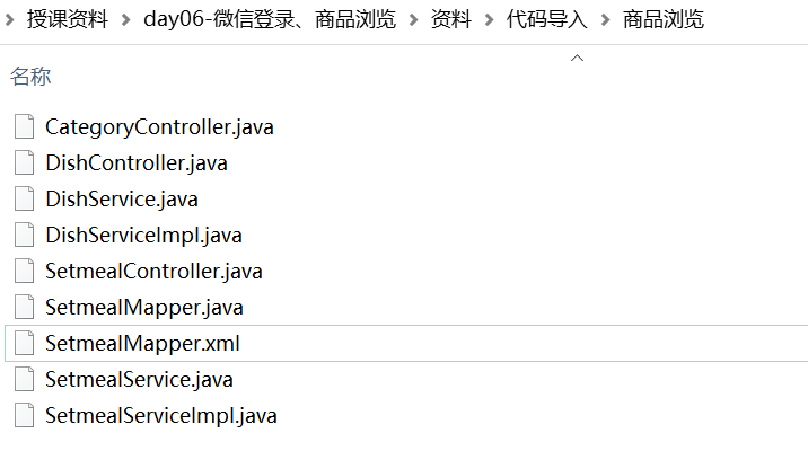 

可按照mapper-->service-->controller依次导入，这样代码不会显示相应的报错。

进入到sky-server模块中

#### 4.2.1 Mapper层

**在SetmealMapper.java中添加list和getDishItemBySetmealId两个方法**

```java
	/**
     * 动态条件查询套餐
     * @param setmeal
     * @return
     */
    List<Setmeal> list(Setmeal setmeal);

    /**
     * 根据套餐id查询菜品选项
     * @param setmealId
     * @return
     */
    @Select("select sd.name, sd.copies, d.image, d.description " +
            "from setmeal_dish sd left join dish d on sd.dish_id = d.id " +
            "where sd.setmeal_id = #{setmealId}")
    List<DishItemVO> getDishItemBySetmealId(Long setmealId);
```

**创建SetmealMapper.xml文件**

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.SetmealMapper">

    <select id="list" parameterType="Setmeal" resultType="Setmeal">
        select * from setmeal
        <where>
            <if test="name != null">
                and name like concat('%',#{name},'%')
            </if>
            <if test="categoryId != null">
                and category_id = #{categoryId}
            </if>
            <if test="status != null">
                and status = #{status}
            </if>
        </where>
    </select>
</mapper>
```


#### 4.2.2 Service层

**创建SetmealService.java**

```java
package com.sky.service;

import com.sky.dto.SetmealDTO;
import com.sky.dto.SetmealPageQueryDTO;
import com.sky.entity.Setmeal;
import com.sky.result.PageResult;
import com.sky.vo.DishItemVO;
import com.sky.vo.SetmealVO;
import java.util.List;

public interface SetmealService {

    /**
     * 条件查询
     * @param setmeal
     * @return
     */
    List<Setmeal> list(Setmeal setmeal);

    /**
     * 根据id查询菜品选项
     * @param id
     * @return
     */
    List<DishItemVO> getDishItemById(Long id);

}
```

**创建SetmealServiceImpl.java**

```java
package com.sky.service.impl;

import com.sky.entity.Setmeal;
import com.sky.mapper.DishMapper;
import com.sky.mapper.SetmealDishMapper;
import com.sky.mapper.SetmealMapper;
import com.sky.service.SetmealService;
import com.sky.vo.DishItemVO;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;

import java.util.List;

/**
 * 套餐业务实现
 */
@Service
@Slf4j
public class SetmealServiceImpl implements SetmealService {

    @Autowired
    private SetmealMapper setmealMapper;
    @Autowired
    private SetmealDishMapper setmealDishMapper;
    @Autowired
    private DishMapper dishMapper;

    /**
     * 条件查询
     * @param setmeal
     * @return
     */
    public List<Setmeal> list(Setmeal setmeal) {
        List<Setmeal> list = setmealMapper.list(setmeal);
        return list;
    }

    /**
     * 根据id查询菜品选项
     * @param id
     * @return
     */
    public List<DishItemVO> getDishItemById(Long id) {
        return setmealMapper.getDishItemBySetmealId(id);
    }
}
```

**在DishService.java中添加listWithFlavor方法定义**

```java
	/**
     * 条件查询菜品和口味
     * @param dish
     * @return
     */
    List<DishVO> listWithFlavor(Dish dish);
```

**在DishServiceImpl.java中实现listWithFlavor方法**

```java
	/**
     * 条件查询菜品和口味
     * @param dish
     * @return
     */
    public List<DishVO> listWithFlavor(Dish dish) {
        List<Dish> dishList = dishMapper.list(dish);

        List<DishVO> dishVOList = new ArrayList<>();

        for (Dish d : dishList) {
            DishVO dishVO = new DishVO();
            BeanUtils.copyProperties(d,dishVO);

            //根据菜品id查询对应的口味
            List<DishFlavor> flavors = dishFlavorMapper.getByDishId(d.getId());

            dishVO.setFlavors(flavors);
            dishVOList.add(dishVO);
        }

        return dishVOList;
    }
```


#### 4.2.3 Controller层

**创建DishController.java**

```java
package com.sky.controller.user;

import com.sky.constant.StatusConstant;
import com.sky.entity.Dish;
import com.sky.result.Result;
import com.sky.service.DishService;
import com.sky.vo.DishVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.util.List;

@RestController("userDishController")
@RequestMapping("/user/dish")
@Slf4j
@Api(tags = "C端-菜品浏览接口")
public class DishController {
    @Autowired
    private DishService dishService;

    /**
     * 根据分类id查询菜品
     *
     * @param categoryId
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("根据分类id查询菜品")
    public Result<List<DishVO>> list(Long categoryId) {
        Dish dish = new Dish();
        dish.setCategoryId(categoryId);
        dish.setStatus(StatusConstant.ENABLE);//查询起售中的菜品

        List<DishVO> list = dishService.listWithFlavor(dish);

        return Result.success(list);
    }

}
```

**创建CategoryController.java**

```java
package com.sky.controller.user;

import com.sky.entity.Category;
import com.sky.result.Result;
import com.sky.service.CategoryService;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.util.List;

@RestController("userCategoryController")
@RequestMapping("/user/category")
@Api(tags = "C端-分类接口")
public class CategoryController {

    @Autowired
    private CategoryService categoryService;

    /**
     * 查询分类
     * @param type
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("查询分类")
    public Result<List<Category>> list(Integer type) {
        List<Category> list = categoryService.list(type);
        return Result.success(list);
    }
}
```

**创建SetmealController.java**

```java
package com.sky.controller.user;

import com.sky.constant.StatusConstant;
import com.sky.entity.Setmeal;
import com.sky.result.Result;
import com.sky.service.SetmealService;
import com.sky.vo.DishItemVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.PathVariable;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.util.List;

@RestController("userSetmealController")
@RequestMapping("/user/setmeal")
@Api(tags = "C端-套餐浏览接口")
public class SetmealController {
    @Autowired
    private SetmealService setmealService;

    /**
     * 条件查询
     *
     * @param categoryId
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("根据分类id查询套餐")
    public Result<List<Setmeal>> list(Long categoryId) {
        Setmeal setmeal = new Setmeal();
        setmeal.setCategoryId(categoryId);
        setmeal.setStatus(StatusConstant.ENABLE);

        List<Setmeal> list = setmealService.list(setmeal);
        return Result.success(list);
    }

    /**
     * 根据套餐id查询包含的菜品列表
     *
     * @param id
     * @return
     */
    @GetMapping("/dish/{id}")
    @ApiOperation("根据套餐id查询包含的菜品列表")
    public Result<List<DishItemVO>> dishList(@PathVariable("id") Long id) {
        List<DishItemVO> list = setmealService.getDishItemById(id);
        return Result.success(list);
    }
}
```


### 导入位置、依赖与遗漏补齐（补充与勘误）

#### 1. 合并已有类，不覆盖管理端功能

讲义写“创建SetmealService、SetmealServiceImpl、SetmealMapper.xml”，但跟练到这里通常已经在前面套餐模块有这些文件。将本章list/getDishItemById方法合并进去，保留原新增、分页、删除、回显、修改、启停售等已有方法；XML同一namespace里增加statement，不创建两个重复id，也不覆盖旧文件。

按Mapper接口与XML、Service、用户端Controller的顺序补齐。用户端Controller与管理端同名时，检查显式Bean名称，避免Spring按短类名产生冲突。

#### 2. 本章调用了DishMapper.list，讲义却没展示它

listWithFlavor第一行依赖 `dishMapper.list(dish)`，该方法可能已在前面套餐选菜等功能中提供；若当前工程缺少它，补到现有DishMapper：

```java
List<Dish> list(Dish dish);
```

在现有DishMapper.xml的mapper节点里增加以下select；已有同名statement时核对并复用，不重复添加。这个补充使用初始工程的Dish类型别名，没配置别名时换成com.sky.entity.Dish：

```xml
<select id="list" parameterType="Dish" resultType="Dish">
    select * from dish
    <where>
        <if test="name != null and name != ''">
            and name like concat('%', #{name}, '%')
        </if>
        <if test="categoryId != null">
            and category_id = #{categoryId}
        </if>
        <if test="status != null">
            and status = #{status}
        </if>
    </where>
    order by create_time desc, id desc
</select>
```

排序是本补充给出的明确顺序；若已有工程约定其他排序，按现有接口统一。DishFlavorMapper.getByDishId来自第03章修改回显功能，CategoryService.list来自分类模块，同样需已有实现。

#### 3. 确认DishItemVO与imports

套餐明细查询返回DishItemVO，初始工程已有时直接复用；若缺少，按原SQL字段补齐最小结构：

```java
package com.sky.vo;

import lombok.Data;
import java.io.Serializable;

@Data
public class DishItemVO implements Serializable {
    private String name;
    private Integer copies;
    private String image;
    private String description;
}
```

copies是该菜品在套餐里的份数，不是购物车数量。SetmealMapper需要导入DishItemVO、List与Select。DishServiceImpl新增方法使用ArrayList、BeanUtils、DishFlavor、DishVO及已注入的DishFlavorMapper，不能只复制方法体却漏依赖。

#### 4. 用户端参数与可见范围

原list(Long categoryId)接收Query，不是Path也不是JSON body。若接口约定categoryId必填，可以显式写 `@RequestParam("categoryId") Long categoryId`并校验大于0；原方法未显式要求必填，null可能使动态SQL不筛分类，返回所有起售商品。

分类type允许省略时返回启用分类；传入时检查1/2。DishController和SetmealController在后端设置status=ENABLE，用户不能通过传status=0要求查看停售商品。

原菜品/套餐list按商品status过滤，但不额外校验目标分类是否启用或类型匹配；若业务要求禁用分类下的商品不能通过直接传id查询，需补分类检查，而不是只依赖首页隐藏分类。

套餐dish/{id}的Service直接查关联行，没有校验套餐存在或起售状态。若用户端只允许查看可售套餐明细，应先检查套餐存在、状态与访问规则，再查明细；原代码不能被理解为已做了这些校验。

#### 5. 菜品口味查询的N+1结构

原方法先查一次菜品，再对每个菜品查一次口味，N个菜品会产生1+N次查询。这是便于教学的组合方式，不是一次SQL查齐所有口味。

分类数据量小时可先正确完成业务；量大时可按菜品id集合批量查询口味，再按dishId分组装配，空id集合不执行IN查询。若以后加缓存，还要处理菜品、口味、分类与状态变化导致的缓存更新，本章尚未实现这些机制。

DishVO.flavors用于决定规格入口。空集合应作为可正常处理的结果，口味value仍沿用前后端约定的字符串格式，不自行改成另一种JSON结构。


### 4.3 功能测试

> **PPT对照：** 第74页。

重启服务器、重新编译小程序

微信登录进入首页

**菜品和套餐分类查询：**

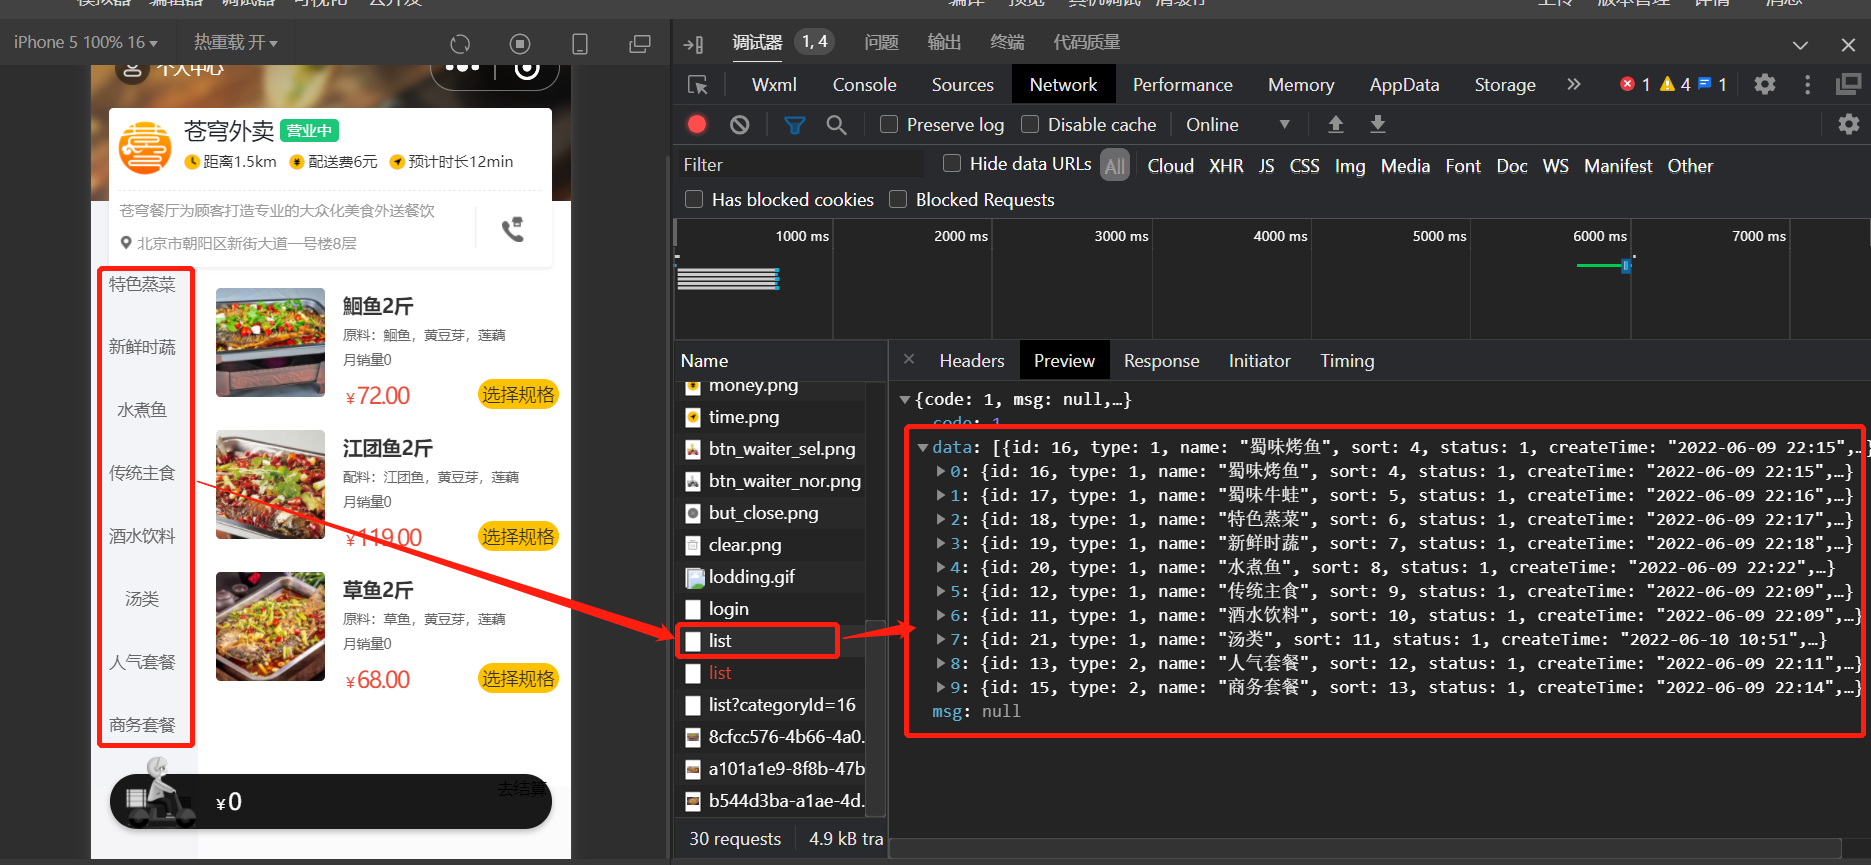 

**具体分类下的菜品查询：**

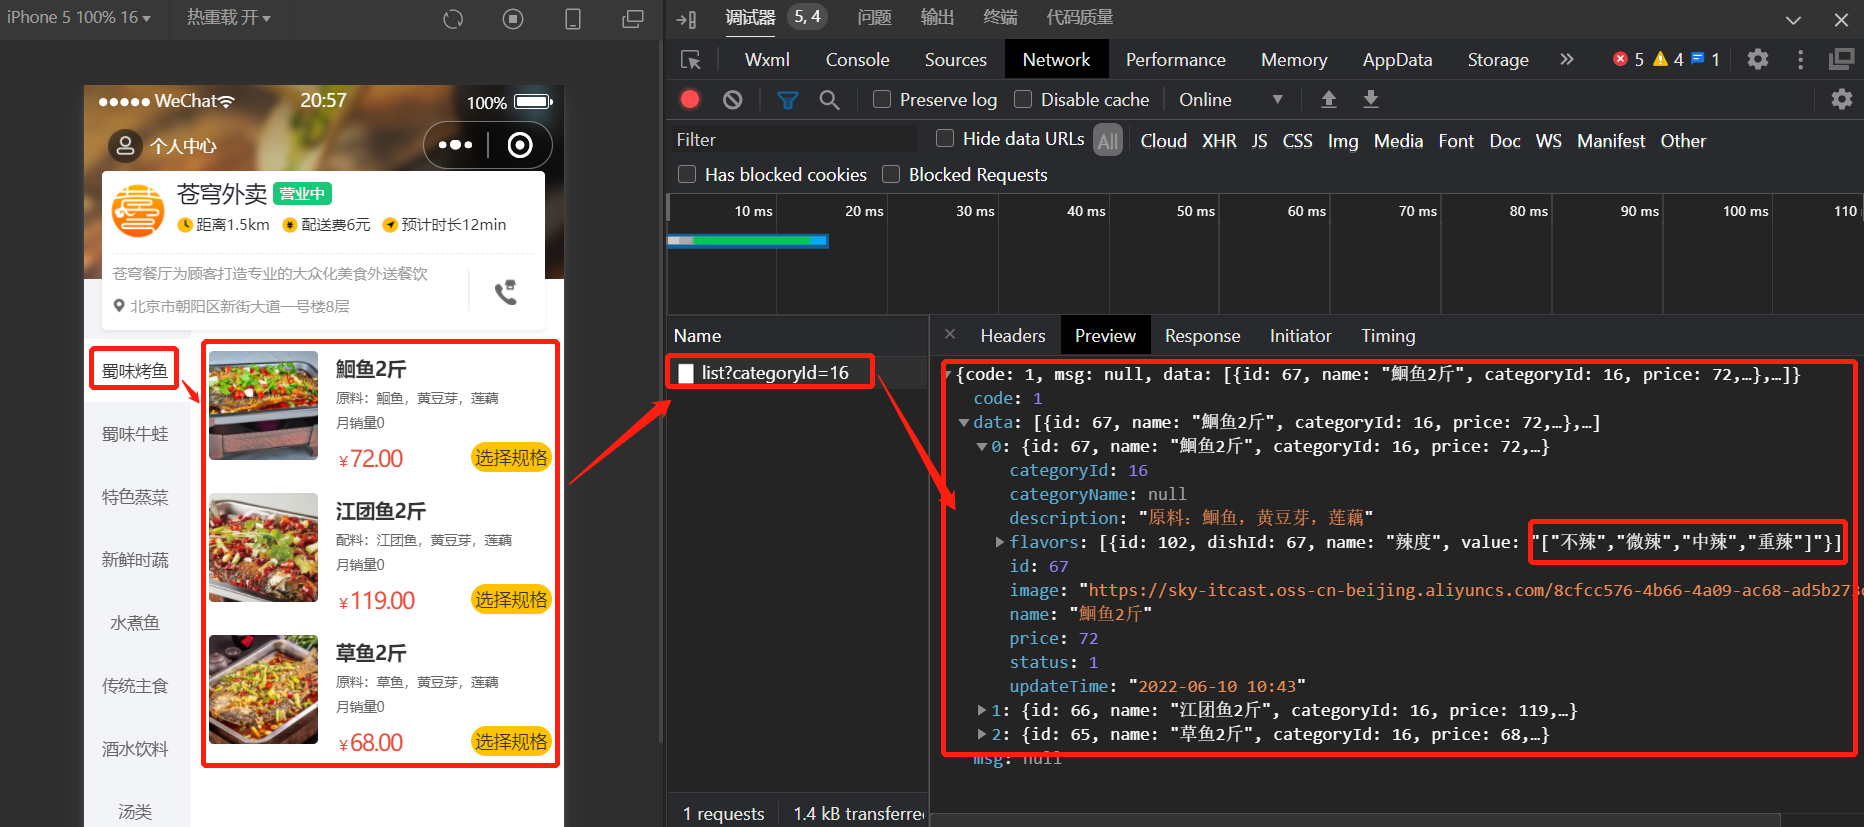 

**菜品口味查询：**

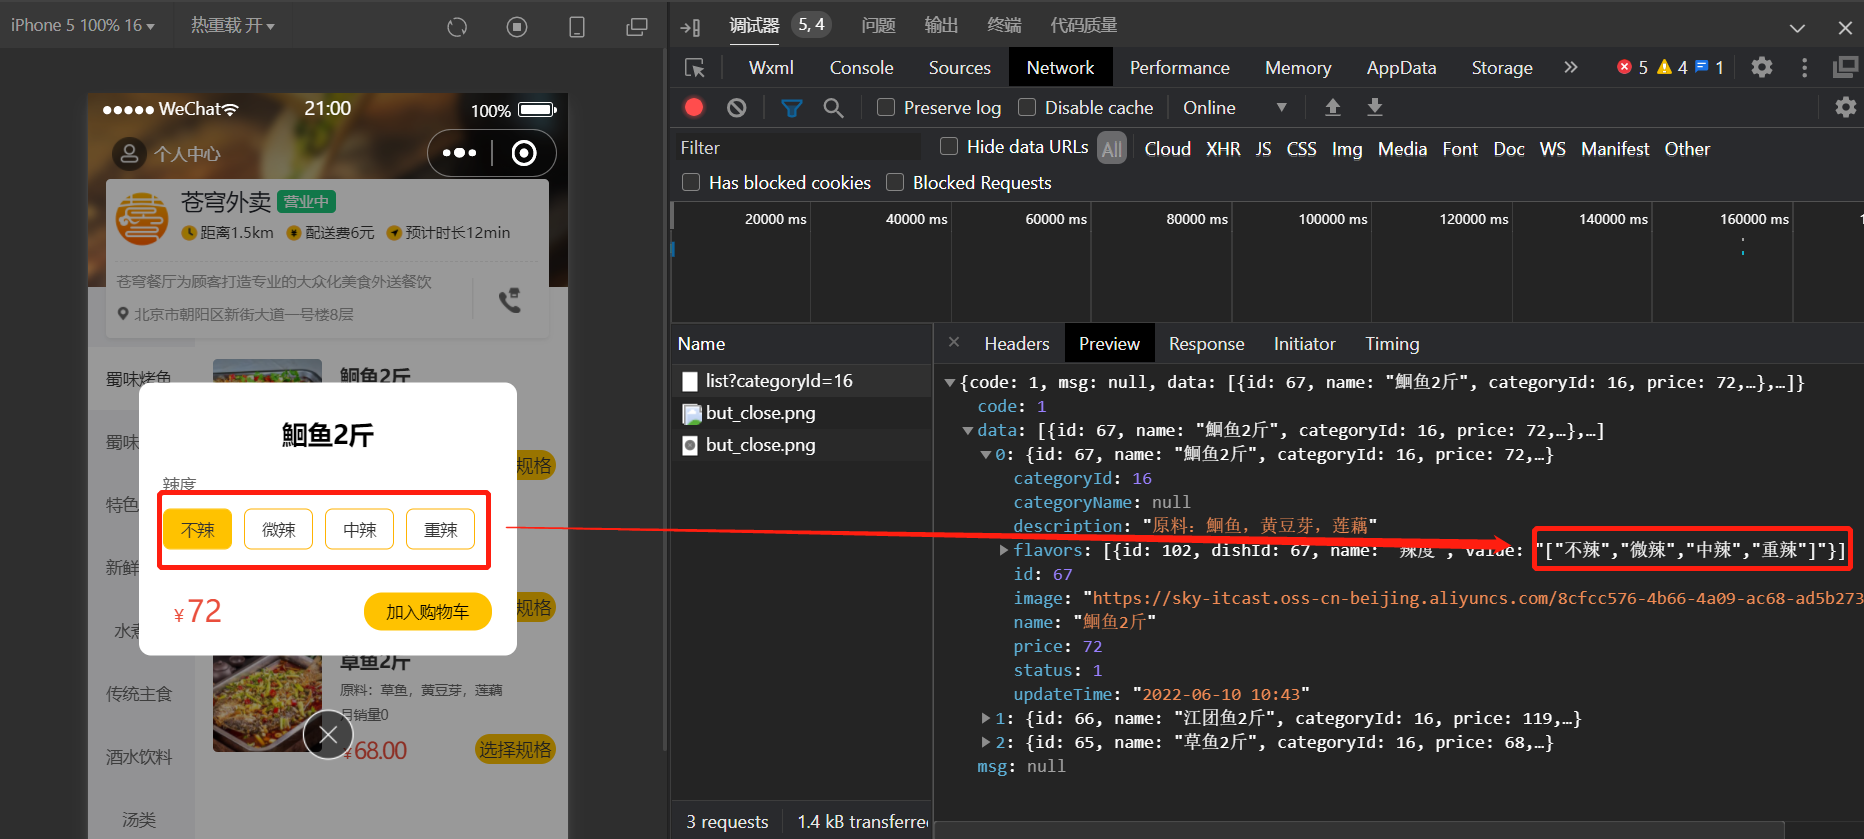


### 商品浏览验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 菜品分类type=1、套餐分类type=2 | 启用项和排序正确，不混淆类型 |
| 有效分类下的菜品 | 只返回起售项，图片和价格正常 |
| 有口味的菜品 | flavors包含全部口味，前端显示规格选择 |
| 无口味的菜品 | 正常空集合，页面显示相应加购入口 |
| 有效分类下的套餐 | 只返回起售项 |
| 套餐明细 | 名称、份数、图片、描述与关联数据匹配 |
| 空分类 | 返回空列表，页面能处理无商品状态 |
| 非法或缺失categoryId | 按接口约定校验，不意外扩大查询范围 |
| 直接查询禁用分类或停售套餐明细 | 按明确的可见范围处理 |
| 缺少或过期用户token | 受保护接口401，触发重新登录 |

从用户端接口文档验证四个接口，再重新编译小程序验证页面。菜单有数据但图片打不开，检查第03章的OSS地址和读取权限；首页没有分类，先查启用状态、type、用户token和分类list，不直接修改前端来掩盖后端筛选问题。

开发阶段可观察SQL次数，确认口味加载来源。明细能展示不表示套餐管理、购物车和下单也已实现；这里只验收本章浏览功能。


### 4.4 代码提交

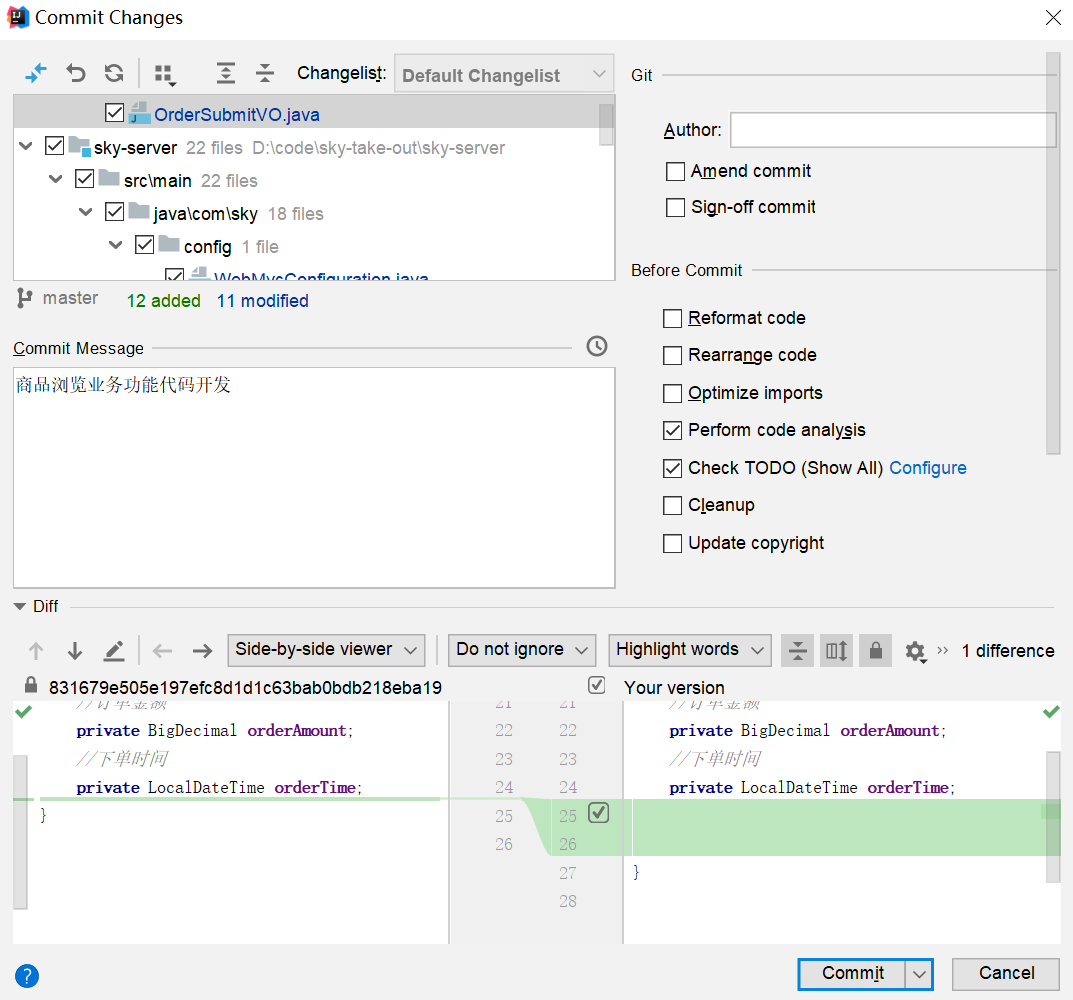 

后续步骤和其它功能代码提交一致，不再赘述。


### 保存本章业务改动时检查范围（补充）

业务工程提交前核对微信配置占位结构、登录实现、拦截器、用户端Controller及合并的查询方法；真实AppSecret通过本地受控配置管理。保留已有管理端代码，避免将讲义的“创建文件”理解成整体替换。

讲义中的提交截图用于说明跟练流程。本次只生成笔记，未对你的业务工程执行数据库写入、代码提交、推送或小程序发布。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| HttpClient | 后端也能作为HTTP客户端请求微信等外部服务 |
| JSON编码 | 构造请求体时指定UTF-8，Content-Encoding不是字符集 |
| 资源管理 | 响应及时关闭，异常路径也关闭；设置合理超时 |
| 小程序页面 | WXML绑定data，setData更新，网络调用是异步 |
| code | wx.login获取，一次使用，失效后重新获取 |
| openid | 当前AppID范围内的微信用户标识 |
| session_key | 服务端微信会话信息，不下发作为业务凭证 |
| 自动注册 | 查openid，没有则插入，回填user.id |
| 用户JWT | userId声明，用户签名配置，authentication请求头 |
| BaseContext | 本次请求的user.id，请求结束及拒绝时清理 |
| 商品浏览 | 启用分类、起售商品、菜品口味和套餐份数 |
| 代码导入 | 合并已有Mapper/Service，不能覆盖前面管理功能 |

### 常见问题排查

| 表现 | 优先检查 |
| --- | --- |
| HTTP连接被拒绝 | 后端是否独立启动、地址、端口、模拟器/真机网络 |
| JSON中文乱码或异常header | StringEntity创建时的charset与Content-Type |
| 小程序success里没有业务data | HTTP状态、Result.code和响应结构 |
| code been used或invalid code | 获取新code，不重复微信测试与后端登录 |
| 微信返回openid为空 | AppID/Secret对应、errcode、网络响应和参数 |
| 新用户返回id为空 | insert的主键回填配置 |
| 重复注册 | openid唯一约束及并发冲突处理 |
| 用户接口401 | authentication请求头、用户密钥、过期、userId声明 |
| 用户id日志没有值 | 日志消息缺少{}占位符 |
| 下一个请求出现旧身份 | ThreadLocal清理及失败分支 |
| 用户Controller名称冲突 | 显式Bean名称与已有管理端类 |
| Mapper没有list statement | DishMapper接口、namespace与XML遗漏 |
| 前面套餐管理方法消失 | 导入时覆盖了已有Service或XML |
| 有菜品却没有规格按钮 | flavors是否查询、口味value是否符合前端约定 |
| 商品页查不到数据 | 分类类型、启用/起售状态、categoryId及用户鉴权 |

### 跟练验收清单

- [ ] GET和JSON POST能发送，处理异常、状态码、编码与响应关闭。
- [ ] 小程序项目能编译，AppID与baseUri对应自己的环境。
- [ ] 说明code、openid、session_key和业务token分别由谁提供。
- [ ] 第一次登录自动注册并回填id，再次登录复用同一账号。
- [ ] 无效code或微信调用错误不会注册空openid或签发token。
- [ ] 用户JWT使用独立配置，通过authentication传递并验签。
- [ ] 登录与营业状态按原约定放行，商品浏览要求有效用户身份。
- [ ] 原code/token日志已在业务跟练中按补充规则调整，上下文会清理。
- [ ] 商品浏览方法合并到已有类，原管理功能保留。
- [ ] DishMapper.list、DishFlavor查询与DishItemVO依赖齐全。
- [ ] 四个浏览接口、口味、套餐份数、空结果与异常输入都已核对。
- [ ] 明确分类和套餐明细可见范围，未把前端隐藏当作后端校验。

### 自测问题

1. Controller接收小程序请求时，为什么后端还要使用HttpClient？
2. Content-Encoding与JSON字符集配置有什么不同？
3. HTTP 200、wx.request的success与业务code成功有什么区别？
4. 真机里的localhost为什么通常访问不到开发电脑上的后端？
5. 用Postman向微信消费过的code，为什么不能再发送给自己的登录接口？
6. openid是否在所有小程序之间都相同？unionid是否总会返回？
7. 登录只有code，为什么user表中的头像昵称不会自动填满？
8. 主键回填为何影响新用户token里的userId？
9. “先查不存在再insert”为什么仍可能重复注册？
10. 用户token返回字段叫token，后续请求头为什么叫authentication？
11. preHandle拒绝请求时，为什么不能只依赖afterCompletion清理？
12. 导入SetmealServiceImpl时直接替换整个文件会丢失什么？
13. listWithFlavor为什么会产生1+N次查询？
14. 套餐明细名称与图片分别从哪张表取得？
15. 首页隐藏了禁用分类，为什么直接按分类id请求仍可能返回商品？

后续商品缓存与购物车将继续使用用户token、商品与口味数据，以及第05章的Redis知识。
